In [ ]:
# Cell 1: Install dependencies
!pip install torch torchvision timm grad-cam scikit-learn matplotlib seaborn pandas numpy pillow -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 59.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# Cell 2: Import semua library yang dibutuhkan
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from collections import Counter

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms, models
import timm

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix
)
from sklearn.utils.class_weight import compute_class_weight

# Cek GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device yang digunakan: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Memory GPU: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

Device yang digunakan: cuda
GPU: Tesla T4
Memory GPU: 15.64 GB


In [ ]:
# Cari file ZIP di seluruh Google Drive
from google.colab import drive
import os

drive.mount('/content/drive')

print("Mencari file ZIP di Google Drive...")
print("Mohon tunggu...\n")

zip_found = []
for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.endswith('.zip'):
            full_path = os.path.join(root, file)
            size_mb = os.path.getsize(full_path) / 1e6
            zip_found.append((full_path, size_mb))
            print(f"Ditemukan : {full_path}")
            print(f"Ukuran    : {size_mb:.1f} MB\n")

if not zip_found:
    print("❌ Tidak ada file ZIP ditemukan!")
    print("File ZIP perlu diupload ulang ke Google Drive teman")
else:
    print(f"Total ZIP ditemukan: {len(zip_found)}")

Mounted at /content/drive
Mencari file ZIP di Google Drive...
Mohon tunggu...

Ditemukan : /content/drive/MyDrive/Tugas_ABP_Week_12/Tugas_Week_12.zip
Ukuran    : 27.8 MB

Ditemukan : /content/drive/MyDrive/TA/dataset/archive (2).zip
Ukuran    : 250.6 MB

Ditemukan : /content/drive/MyDrive/TA/code_model/archive (2).zip
Ukuran    : 250.6 MB

Ditemukan : /content/drive/MyDrive/TA/code_model/outputs_swinconvnext.zip
Ukuran    : 623.8 MB

Ditemukan : /content/drive/MyDrive/TA/code_model/outputs_densenet.zip
Ukuran    : 83.2 MB

Ditemukan : /content/drive/MyDrive/TA/code_model/outputs_efficientnet.zip
Ukuran    : 52.1 MB

Ditemukan : /content/drive/MyDrive/TA/code_model/outputs_vit.zip
Ukuran    : 962.9 MB

Total ZIP ditemukan: 7


In [ ]:
# Cell 3: Mount Google Drive + Setup path yang benar

from google.colab import drive
import zipfile
import os

# Mount Google Drive
drive.mount('/content/drive')

# Path ZIP yang baru (sudah dipindahkan)
ZIP_PATH = '/content/drive/MyDrive/TA/dataset/archive (2).zip'

# Path tujuan ekstrak
EXTRACT_PATH = '/content/dataset'

# Verifikasi
print(f"ZIP_PATH     : {ZIP_PATH}")
print(f"ZIP exists   : {os.path.exists(ZIP_PATH)}")

if os.path.exists(ZIP_PATH):
    print(f"ZIP size     : {os.path.getsize(ZIP_PATH) / 1e6:.1f} MB")
    print("✅ File ZIP ditemukan!")
else:
    print("❌ File tidak ditemukan, cek path!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ZIP_PATH     : /content/drive/MyDrive/TA/dataset/archive (2).zip
ZIP exists   : True
ZIP size     : 250.6 MB
✅ File ZIP ditemukan!


In [ ]:
# Cell 3B: Extract ZIP (jalankan sekali saja)

if not os.path.exists(EXTRACT_PATH):
    print("Mengekstrak dataset, mohon tunggu...")
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_PATH)
    print("Ekstrak selesai!")
else:
    print("Dataset sudah diekstrak sebelumnya, skip.")

# Cek hasil ekstrak
print("\nStruktur folder hasil ekstrak:")
for root, dirs, files in os.walk(EXTRACT_PATH):
    level = root.replace(EXTRACT_PATH, '').count(os.sep)
    if level > 2:  # Batasi kedalaman tampilan
        continue
    indent = '  ' * level
    print(f"{indent}{os.path.basename(root)}/")
    if level == 1:
        print(f"{'  ' * (level+1)}({len(files)} files)")

Mengekstrak dataset, mohon tunggu...
Ekstrak selesai!

Struktur folder hasil ekstrak:
dataset/
  garbage_classification/
    (0 files)
    cardboard/
    trash/
    paper/
    white-glass/
    clothes/
    plastic/
    metal/
    battery/
    biological/
    brown-glass/
    green-glass/
    shoes/


In [ ]:
# Cell 3C: Temukan path yang benar dan set DATASET_PATH

# Scan semua folder di hasil ekstrak
print("Mencari folder kelas dataset...")
print()

for root, dirs, files in os.walk(EXTRACT_PATH):
    # Cari folder yang berisi gambar
    img_files = [f for f in files if f.lower().endswith(
        ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
    )]
    if img_files:
        print(f"Folder dengan gambar: {root}")
        print(f"  Jumlah gambar: {len(img_files)}")
        print(f"  Contoh: {img_files[0]}")
        print()

Mencari folder kelas dataset...

Folder dengan gambar: /content/dataset/garbage_classification/cardboard
  Jumlah gambar: 891
  Contoh: cardboard343.jpg

Folder dengan gambar: /content/dataset/garbage_classification/trash
  Jumlah gambar: 697
  Contoh: trash546.jpg

Folder dengan gambar: /content/dataset/garbage_classification/paper
  Jumlah gambar: 1050
  Contoh: paper400.jpg

Folder dengan gambar: /content/dataset/garbage_classification/white-glass
  Jumlah gambar: 775
  Contoh: white-glass51.jpg

Folder dengan gambar: /content/dataset/garbage_classification/clothes
  Jumlah gambar: 5325
  Contoh: clothes2210.jpg

Folder dengan gambar: /content/dataset/garbage_classification/plastic
  Jumlah gambar: 865
  Contoh: plastic586.jpg

Folder dengan gambar: /content/dataset/garbage_classification/metal
  Jumlah gambar: 769
  Contoh: metal96.jpg

Folder dengan gambar: /content/dataset/garbage_classification/battery
  Jumlah gambar: 945
  Contoh: battery529.jpg

Folder dengan gambar: /content

In [ ]:
# Cell 4: Definisi mapping dari 12 kelas ke 2 kelas (Organik & Anorganik)

# Mapping sesuai proposal penelitian Anda
LABEL_MAPPING = {
    'biological': 0,   # Organik
    'trash': 0,        # Organik
    'battery': 1,      # Anorganik
    'brown-glass': 1,  # Anorganik
    'cardboard': 1,    # Anorganik
    'clothes': 1,      # Anorganik
    'green-glass': 1,  # Anorganik
    'metal': 1,        # Anorganik
    'paper': 1,        # Anorganik
    'plastic': 1,      # Anorganik
    'shoes': 1,        # Anorganik
    'white-glass': 1,  # Anorganik
}

CLASS_NAMES = {0: 'Organic', 1: 'Inorganic'}
print("Label Mapping:")
for k, v in LABEL_MAPPING.items():
    print(f"  {k:15s} -> {v} ({CLASS_NAMES[v]})")

Label Mapping:
  biological      -> 0 (Organic)
  trash           -> 0 (Organic)
  battery         -> 1 (Inorganic)
  brown-glass     -> 1 (Inorganic)
  cardboard       -> 1 (Inorganic)
  clothes         -> 1 (Inorganic)
  green-glass     -> 1 (Inorganic)
  metal           -> 1 (Inorganic)
  paper           -> 1 (Inorganic)
  plastic         -> 1 (Inorganic)
  shoes           -> 1 (Inorganic)
  white-glass     -> 1 (Inorganic)


In [ ]:
# Cell 3D: Set DATASET_PATH yang benar berdasarkan hasil scan

DATASET_PATH = '/content/dataset/garbage_classification'

print(f"DATASET_PATH = {DATASET_PATH}")
print(f"Path exists  = {os.path.exists(DATASET_PATH)}")
print(f"Isi folder   = {os.listdir(DATASET_PATH)}")

DATASET_PATH = /content/dataset/garbage_classification
Path exists  = True
Isi folder   = ['cardboard', 'trash', 'paper', 'white-glass', 'clothes', 'plastic', 'metal', 'battery', 'biological', 'brown-glass', 'green-glass', 'shoes']


In [ ]:
# Cell 5: Load dan scan seluruh dataset

def scan_dataset(dataset_path, label_mapping):
    """Scan folder dataset dan buat daftar (path, label)"""
    data = []
    skipped = 0

    for class_folder in os.listdir(dataset_path):
        class_path = os.path.join(dataset_path, class_folder)

        if not os.path.isdir(class_path):
            continue

        # Normalize nama folder (lowercase, strip spasi)
        class_name = class_folder.lower().strip()

        if class_name not in label_mapping:
            print(f"  [WARNING] Folder '{class_folder}' tidak ada di mapping, dilewati")
            skipped += 1
            continue

        label = label_mapping[class_name]

        for img_file in os.listdir(class_path):
            if img_file.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp')):
                img_path = os.path.join(class_path, img_file)

                # Cek apakah gambar bisa dibuka
                try:
                    img = Image.open(img_path)
                    img.verify()
                    data.append({
                        'path': img_path,
                        'original_class': class_name,
                        'label': label
                    })
                except Exception:
                    skipped += 1

    return pd.DataFrame(data), skipped

df, skipped = scan_dataset(DATASET_PATH, LABEL_MAPPING)

print("=" * 50)
print("HASIL SCAN DATASET")
print("=" * 50)
print(f"Total gambar valid    : {len(df)}")
print(f"Gambar dilewati/rusak : {skipped}")
print()
print("Distribusi per kelas original:")
for cls, count in df['original_class'].value_counts().items():
    label = LABEL_MAPPING.get(cls, '?')
    print(f"  {cls:15s}: {count:5d} gambar -> {CLASS_NAMES[label]}")
print()
print("Distribusi setelah relabeling:")
for label, count in df['label'].value_counts().sort_index().items():
    pct = count / len(df) * 100
    print(f"  {CLASS_NAMES[label]:10s} (label {label}): {count:5d} gambar ({pct:.2f}%)")

HASIL SCAN DATASET
Total gambar valid    : 15515
Gambar dilewati/rusak : 0

Distribusi per kelas original:
  clothes        :  5325 gambar -> Inorganic
  shoes          :  1977 gambar -> Inorganic
  paper          :  1050 gambar -> Inorganic
  biological     :   985 gambar -> Organic
  battery        :   945 gambar -> Inorganic
  cardboard      :   891 gambar -> Inorganic
  plastic        :   865 gambar -> Inorganic
  white-glass    :   775 gambar -> Inorganic
  metal          :   769 gambar -> Inorganic
  trash          :   697 gambar -> Organic
  green-glass    :   629 gambar -> Inorganic
  brown-glass    :   607 gambar -> Inorganic

Distribusi setelah relabeling:
  Organic    (label 0):  1682 gambar (10.84%)
  Inorganic  (label 1): 13833 gambar (89.16%)


In [ ]:
# Cell 6: Split dataset -> Train 70%, Validation 15%, Test 15%
from sklearn.model_selection import train_test_split

# Split pertama: pisahkan test set (15%)
df_train_val, df_test = train_test_split(
    df,
    test_size=0.15,
    random_state=42,
    stratify=df['label']  # Pastikan proporsi kelas sama di setiap split
)

# Split kedua: pisahkan train dan validation dari sisa data
# 15% dari total = 15/85 dari train_val
df_train, df_val = train_test_split(
    df_train_val,
    test_size=0.15/0.85,
    random_state=42,
    stratify=df_train_val['label']
)

print("=" * 50)
print("HASIL SPLIT DATASET")
print("=" * 50)
for split_name, split_df in [('Train', df_train), ('Validation', df_val), ('Test', df_test)]:
    total = len(split_df)
    organic = (split_df['label'] == 0).sum()
    inorganic = (split_df['label'] == 1).sum()
    print(f"\n{split_name} Set: {total} gambar")
    print(f"  Organic   : {organic:4d} ({organic/total*100:.1f}%)")
    print(f"  Inorganic : {inorganic:4d} ({inorganic/total*100:.1f}%)")

# Reset index
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

HASIL SPLIT DATASET

Train Set: 10859 gambar
  Organic   : 1178 (10.8%)
  Inorganic : 9681 (89.2%)

Validation Set: 2328 gambar
  Organic   :  252 (10.8%)
  Inorganic : 2076 (89.2%)

Test Set: 2328 gambar
  Organic   :  252 (10.8%)
  Inorganic : 2076 (89.2%)


In [ ]:
# Cell 7: Hitung class weights untuk menangani imbalance

labels_train = df_train['label'].values

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(labels_train),
    y=labels_train
)

class_weight_tensor = torch.tensor(class_weights, dtype=torch.float).to(device)

print("=" * 50)
print("CLASS WEIGHTS UNTUK WEIGHTED LOSS")
print("=" * 50)
print(f"  Organic   (0): {class_weights[0]:.4f}")
print(f"  Inorganic (1): {class_weights[1]:.4f}")
print()
print("Interpretasi:")
print(f"  Loss untuk gambar Organic dikalikan {class_weights[0]:.2f}x")
print(f"  Loss untuk gambar Inorganic dikalikan {class_weights[1]:.2f}x")
print()

# Hitung juga sample weights untuk WeightedRandomSampler
sample_weights = np.array([
    class_weights[label] for label in labels_train
])
sample_weights_tensor = torch.tensor(sample_weights, dtype=torch.float)

print("Sample weights siap untuk WeightedRandomSampler")

CLASS WEIGHTS UNTUK WEIGHTED LOSS
  Organic   (0): 4.6091
  Inorganic (1): 0.5608

Interpretasi:
  Loss untuk gambar Organic dikalikan 4.61x
  Loss untuk gambar Inorganic dikalikan 0.56x

Sample weights siap untuk WeightedRandomSampler


In [ ]:
# Cell 8: Definisi transforms dan custom Dataset class

# Transform untuk training (dengan augmentasi agresif)
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.3),
    transforms.RandomRotation(degrees=30),
    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3,
        saturation=0.2,
        hue=0.1
    ),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.1, 0.1),
        scale=(0.9, 1.1)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Transform untuk validasi dan test (tanpa augmentasi)
val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Custom Dataset Class
class WasteDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.iloc[idx]['path']
        label = self.df.iloc[idx]['label']

        try:
            image = Image.open(img_path).convert('RGB')
        except Exception:
            # Jika gambar rusak, return gambar hitam
            image = Image.new('RGB', (224, 224), color=0)

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

print("Transform dan Dataset class berhasil didefinisikan")
print(f"\nAugmentasi training: 7 teknik")
print("  - Resize + RandomCrop")
print("  - RandomHorizontalFlip")
print("  - RandomVerticalFlip")
print("  - RandomRotation")
print("  - ColorJitter")
print("  - RandomAffine")
print("  - Normalize")

Transform dan Dataset class berhasil didefinisikan

Augmentasi training: 7 teknik
  - Resize + RandomCrop
  - RandomHorizontalFlip
  - RandomVerticalFlip
  - RandomRotation
  - ColorJitter
  - RandomAffine
  - Normalize


In [ ]:
# Cell 9: Buat DataLoader dengan WeightedRandomSampler

BATCH_SIZE = 16

# Dataset
train_dataset = WasteDataset(df_train, transform=train_transform)
val_dataset   = WasteDataset(df_val,   transform=val_test_transform)
test_dataset  = WasteDataset(df_test,  transform=val_test_transform)

# WeightedRandomSampler untuk oversampling kelas minoritas
sampler = WeightedRandomSampler(
    weights=sample_weights_tensor,
    num_samples=len(sample_weights_tensor),
    replacement=True
)

# DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,       # Gunakan sampler, bukan shuffle
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("=" * 50)
print("DATALOADER BERHASIL DIBUAT")
print("=" * 50)
print(f"Batch size        : {BATCH_SIZE}")
print(f"Train batches     : {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Test batches      : {len(test_loader)}")
print()
print("WeightedRandomSampler aktif:")
print("  Kelas Organic akan lebih sering muncul di training")

DATALOADER BERHASIL DIBUAT
Batch size        : 16
Train batches     : 679
Validation batches: 146
Test batches      : 146

WeightedRandomSampler aktif:
  Kelas Organic akan lebih sering muncul di training


In [ ]:
# Cell 10: Definisi arsitektur SwinConvNeXt
# Urutan sesuai paper acuan:
# Input -> Swin Transformer -> ConvNeXt -> Spatial Attention -> Classifier

class SpatialAttention(nn.Module):
    """Spatial Attention Mechanism"""
    def __init__(self, in_channels):
        super(SpatialAttention, self).__init__()
        self.conv = nn.Conv2d(
            in_channels=2,
            out_channels=1,
            kernel_size=7,
            padding=3,
            bias=False
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_pool = torch.mean(x, dim=1, keepdim=True)
        max_pool, _ = torch.max(x, dim=1, keepdim=True)
        pooled = torch.cat([avg_pool, max_pool], dim=1)
        attention = self.sigmoid(self.conv(pooled))
        return x * attention


class SwinConvNeXt(nn.Module):
    """
    Hybrid SwinConvNeXt Model
    Urutan: Swin Transformer -> ConvNeXt -> Spatial Attention -> Classifier
    """
    def __init__(self, num_classes=2, dropout_rate=0.3):
        super(SwinConvNeXt, self).__init__()

        # === STEP 1: Enhanced Swin Transformer (Global Features) ===
        self.swin = timm.create_model(
            'swin_tiny_patch4_window7_224',
            pretrained=True,
            num_classes=0,      # Hapus classification head
            global_pool=''      # Pertahankan feature map
        )
        swin_out_dim = 768      # Output channels Swin-Tiny

        # === STEP 2: Improved ConvNeXt Block (Local Features) ===
        self.convnext = timm.create_model(
            'convnext_tiny',
            pretrained=True,
            num_classes=0,      # Hapus classification head
            global_pool=''      # Pertahankan feature map
        )
        convnext_out_dim = 768  # Output channels ConvNeXt-Tiny

        # Projection layer untuk menyamakan dimensi sebelum fusion
        self.swin_proj = nn.Sequential(
            nn.AdaptiveAvgPool2d(7),
            nn.Flatten(),
            nn.Linear(swin_out_dim * 7 * 7, 512),
            nn.LayerNorm(512),
            nn.GELU()
        )

        self.convnext_proj = nn.Sequential(
            nn.AdaptiveAvgPool2d(7),
            nn.Flatten(),
            nn.Linear(convnext_out_dim * 7 * 7, 512),
            nn.LayerNorm(512),
            nn.GELU()
        )

        # === STEP 3: Feature Fusion ===
        self.fusion = nn.Sequential(
            nn.Linear(1024, 512),
            nn.LayerNorm(512),
            nn.GELU(),
            nn.Dropout(dropout_rate)
        )

        # === STEP 4: Classification Head ===
        self.classifier = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        # Step 1: Swin Transformer -> Global features
        swin_feat = self.swin.forward_features(x)
        # swin output shape: (B, H, W, C) -> permute ke (B, C, H, W)
        if swin_feat.dim() == 4:
            swin_feat = swin_feat.permute(0, 3, 1, 2)

        # Step 2: ConvNeXt -> Local features
        convnext_feat = self.convnext.forward_features(x)

        # Step 3: Project ke dimensi yang sama
        swin_out = self.swin_proj(swin_feat)
        convnext_out = self.convnext_proj(convnext_feat)

        # Step 4: Concatenate dan fuse
        fused = torch.cat([swin_out, convnext_out], dim=1)
        fused = self.fusion(fused)

        # Step 5: Classification
        out = self.classifier(fused)
        return out


# Inisialisasi model
model = SwinConvNeXt(num_classes=2, dropout_rate=0.3).to(device)

# Hitung total parameter
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("=" * 50)
print("MODEL SWINCONVNEXT BERHASIL DIBUAT")
print("=" * 50)
print(f"Total parameters    : {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Model ada di        : {device}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

MODEL SWINCONVNEXT BERHASIL DIBUAT
Total parameters    : 94,535,388
Trainable parameters: 94,535,388
Model ada di        : cuda


In [ ]:
# ============================================================
# ABLATION STUDY: Pengaruh Weighted Loss & Oversampling
# Tambahkan setelah Cell 14 (training SwinConvNeXt asli)
# ============================================================

import copy

ABLATION_SAVE_DIR = '/content/drive/MyDrive/TA/file_pth/ablation'
os.makedirs(ABLATION_SAVE_DIR, exist_ok=True)

# --- DataLoader TANPA WeightedRandomSampler (no oversampling) ---
train_loader_no_os = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,         # shuffle biasa, tanpa sampler
    num_workers=2,
    pin_memory=True
)

# --- Loss TANPA class weights (no weighted loss) ---
criterion_no_wl = nn.CrossEntropyLoss()   # bobot seragam

# ============================================================
# Eksperimen 1: WITHOUT Weighted Loss (pakai oversampling biasa)
# ============================================================
print("\n" + "="*55)
print("ABLATION 1: WITHOUT Weighted Loss")
print("="*55)

model_abl1 = SwinConvNeXt(num_classes=2, dropout_rate=0.3).to(device)

# Modifikasi train_model: inject criterion manual
def train_model_ablation(model, model_name, train_loader, val_loader,
                          criterion, device, num_epochs=75, patience=10, lr=1e-4):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)
    best_macro_f1 = 0
    patience_counter = 0
    best_state = None
    history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_macro_f1': []}

    for epoch in range(num_epochs):
        # Train
        model.train()
        total_loss, all_preds, all_labels = 0, [], []
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            all_preds.extend(outputs.argmax(1).cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
        scheduler.step()

        # Validate
        model.eval()
        val_loss, val_preds, val_labels = 0, [], []
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                val_loss += criterion(outputs, labels).item()
                val_preds.extend(outputs.argmax(1).cpu().numpy())
                val_labels.extend(labels.cpu().numpy())

        from sklearn.metrics import accuracy_score, f1_score
        val_acc = accuracy_score(val_labels, val_preds)
        val_macro_f1 = f1_score(val_labels, val_preds, average='macro')
        history['train_loss'].append(total_loss / len(train_loader))
        history['val_loss'].append(val_loss / len(val_loader))
        history['val_acc'].append(val_acc)
        history['val_macro_f1'].append(val_macro_f1)

        if val_macro_f1 > best_macro_f1:
            best_macro_f1 = val_macro_f1
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1:3d} | Val Acc: {val_acc:.4f} | Macro F1: {val_macro_f1:.4f}")

        if patience_counter >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

    model.load_state_dict(best_state)
    torch.save(best_state, os.path.join(ABLATION_SAVE_DIR, f'ablation_{model_name}.pth'))
    print(f"\n✅ Best Macro F1: {best_macro_f1:.4f}")
    return model, history

model_abl1, history_abl1 = train_model_ablation(
    model_abl1, 'no_weighted_loss',
    train_loader,       # pakai sampler (oversampling ON)
    val_loader,
    criterion_no_wl,   # weighted loss OFF
    device
)

# ============================================================
# Eksperimen 2: WITHOUT Oversampling (pakai weighted loss biasa)
# ============================================================
print("\n" + "="*55)
print("ABLATION 2: WITHOUT Oversampling")
print("="*55)

model_abl2 = SwinConvNeXt(num_classes=2, dropout_rate=0.3).to(device)
criterion_with_wl = nn.CrossEntropyLoss(weight=class_weight_tensor.to(device))

model_abl2, history_abl2 = train_model_ablation(
    model_abl2, 'no_oversampling',
    train_loader_no_os,  # oversampling OFF
    val_loader,
    criterion_with_wl,   # weighted loss ON
    device
)
print("\n✅ Semua ablation training selesai!")


ABLATION 1: WITHOUT Weighted Loss
Epoch  10 | Val Acc: 0.9863 | Macro F1: 0.9652
Early stopping at epoch 18

✅ Best Macro F1: 0.9790

ABLATION 2: WITHOUT Oversampling
Epoch  10 | Val Acc: 0.9695 | Macro F1: 0.9274
Early stopping at epoch 15

✅ Best Macro F1: 0.9573

✅ Semua ablation training selesai!


In [ ]:
# Load full model SwinConvNeXt (untuk perbandingan ablation)
MODEL_DIR = '/content/drive/MyDrive/TA/file_pth'

model_swin = SwinConvNeXt(num_classes=2, dropout_rate=0.3).to(device)
model_swin.load_state_dict(torch.load(
    os.path.join(MODEL_DIR, 'best_swinconvnext.pth'),
    map_location=device
))
model_swin.eval()
print("✅ Full model loaded!")

✅ Full model loaded!


In [ ]:
# ============================================================
# ABLATION STUDY: Evaluasi & Tabel Perbandingan
# ============================================================
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, recall_score

def evaluate_ablation(model, loader, device):
    model.eval()
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for imgs, lbls in loader:
            imgs = imgs.to(device)
            out  = model(imgs)
            prob = torch.softmax(out, dim=1)[:, 1].cpu().numpy()
            pred = out.argmax(1).cpu().numpy()
            all_preds.extend(pred)
            all_labels.extend(lbls.numpy())
            all_probs.extend(prob)
    return {
        'accuracy'  : accuracy_score(all_labels, all_preds) * 100,
        'macro_f1'  : f1_score(all_labels, all_preds, average='macro') * 100,
        'f1'        : f1_score(all_labels, all_preds, average='weighted') * 100,
        'org_recall': recall_score(all_labels, all_preds, pos_label=0) * 100,
        'roc_auc'   : roc_auc_score(all_labels, all_probs) * 100,
    }

# Evaluasi semua kondisi
print("Evaluating...")
res_full = evaluate_ablation(model_swin,  test_loader, device)
res_abl1 = evaluate_ablation(model_abl1, test_loader, device)
res_abl2 = evaluate_ablation(model_abl2, test_loader, device)

# Tabel hasil
print("\n" + "="*80)
print("ABLATION STUDY RESULTS")
print("="*80)
print(f"{'Configuration':<35} {'Accuracy':>9} {'F1':>8} {'Macro F1':>9} {'Org Recall':>11} {'ROC-AUC':>9}")
print("-"*80)
for name, res in [
    ("Full Model (WL + OS)",          res_full),
    ("Without Weighted Loss (WL off)", res_abl1),
    ("Without Oversampling (OS off)",  res_abl2),
]:
    print(f"{name:<35} {res['accuracy']:>8.2f}% {res['f1']:>7.2f}% {res['macro_f1']:>8.2f}% {res['org_recall']:>10.2f}% {res['roc_auc']:>8.2f}%")
print("="*80)
print("\n✅ Simpan tabel ini untuk paper!")

Evaluating...

ABLATION STUDY RESULTS
Configuration                        Accuracy       F1  Macro F1  Org Recall   ROC-AUC
--------------------------------------------------------------------------------
Full Model (WL + OS)                   99.40%   99.40%    98.47%      99.60%    99.97%
Without Weighted Loss (WL off)         99.05%   99.07%    97.62%      98.81%    99.78%
Without Oversampling (OS off)          98.63%   98.61%    96.38%      91.67%    99.57%

✅ Simpan tabel ini untuk paper!


In [ ]:
# Cell 11: Definisi model-model baseline (ViT, DenseNet121, EfficientNet-B0)

def create_vit(num_classes=2):
    model = timm.create_model(
        'vit_small_patch16_224',
        pretrained=True,
        num_classes=num_classes
    )
    return model

def create_densenet121(num_classes=2):
    model = models.densenet121(pretrained=True)
    model.classifier = nn.Linear(1024, num_classes)
    return model

def create_efficientnet_b0(num_classes=2):
    model = models.efficientnet_b0(pretrained=True)
    model.classifier[1] = nn.Linear(1280, num_classes)
    return model

# Test inisialisasi semua model
print("Inisialisasi model baseline:")
vit = create_vit().to(device)
print(f"  ViT            : {sum(p.numel() for p in vit.parameters()):,} parameters")
del vit

densenet = create_densenet121().to(device)
print(f"  DenseNet121    : {sum(p.numel() for p in densenet.parameters()):,} parameters")
del densenet

efficientnet = create_efficientnet_b0().to(device)
print(f"  EfficientNet-B0: {sum(p.numel() for p in efficientnet.parameters()):,} parameters")
del efficientnet

print(f"  SwinConvNeXt   : {trainable_params:,} parameters")
print()
print("Semua model berhasil diinisialisasi!")

Inisialisasi model baseline:


model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

  ViT            : 21,666,434 parameters
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=DenseNet121_Weights.IMAGENET1K_V1`. You can also use `weights=DenseNet121_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100%|██████████| 30.8M/30.8M [00:00<00:00, 185MB/s]
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `

  DenseNet121    : 6,955,906 parameters
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 167MB/s]

  EfficientNet-B0: 4,010,110 parameters
  SwinConvNeXt   : 94,535,388 parameters

Semua model berhasil diinisialisasi!


In [ ]:
# Cell 12: Fungsi training dan evaluasi

def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    all_preds, all_labels = [], []

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()

        # Gradient clipping untuk stabilitas training
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()

        total_loss += loss.item()
        preds = torch.argmax(outputs, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader)
    accuracy = accuracy_score(all_labels, all_preds)
    return avg_loss, accuracy


def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    all_preds, all_labels, all_probs = [], [], []

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()
            probs = torch.softmax(outputs, dim=1)[:, 1]
            preds = torch.argmax(outputs, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    avg_loss = total_loss / len(loader)

    metrics = {
        'loss'     : avg_loss,
        'accuracy' : accuracy_score(all_labels, all_preds),
        'precision': precision_score(all_labels, all_preds, average='weighted', zero_division=0),
        'recall'   : recall_score(all_labels, all_preds, average='weighted', zero_division=0),
        'f1'       : f1_score(all_labels, all_preds, average='weighted', zero_division=0),
        'macro_f1' : f1_score(all_labels, all_preds, average='macro', zero_division=0),
        'auc'      : roc_auc_score(all_labels, all_probs),
        'preds'    : all_preds,
        'labels'   : all_labels
    }
    return metrics


print("Fungsi training dan evaluasi berhasil didefinisikan")

Fungsi training dan evaluasi berhasil didefinisikan


In [ ]:
# Cell 13: Fungsi training loop lengkap dengan early stopping

def train_model(model, model_name, train_loader, val_loader,
                class_weight_tensor, device,
                num_epochs=75, patience=10, lr=1e-4):

    print(f"\n{'='*55}")
    print(f"TRAINING: {model_name}")
    print(f"{'='*55}")

    # Loss dengan class weights
    criterion = nn.CrossEntropyLoss(weight=class_weight_tensor)

    # Optimizer
    optimizer = optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=1e-4
    )

    # Learning rate scheduler
    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=num_epochs,
        eta_min=1e-6
    )

    # History untuk plotting
    history = {
        'train_loss': [], 'val_loss': [],
        'train_acc' : [], 'val_acc' : [],
        'val_f1'    : [], 'val_macro_f1': []
    }

    best_val_f1   = 0
    best_model_wts = None
    no_improve     = 0

    for epoch in range(num_epochs):
        # Training
        train_loss, train_acc = train_one_epoch(
            model, train_loader, optimizer, criterion, device
        )

        # Validation
        val_metrics = evaluate(model, val_loader, criterion, device)

        scheduler.step()

        # Simpan history
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_metrics['loss'])
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_metrics['accuracy'])
        history['val_f1'].append(val_metrics['f1'])
        history['val_macro_f1'].append(val_metrics['macro_f1'])

        # Print progress setiap 5 epoch
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"Epoch [{epoch+1:3d}/{num_epochs}] "
                  f"| Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} "
                  f"| Val Loss: {val_metrics['loss']:.4f} "
                  f"Acc: {val_metrics['accuracy']:.4f} "
                  f"F1: {val_metrics['f1']:.4f} "
                  f"MacroF1: {val_metrics['macro_f1']:.4f}")

        # Early stopping berdasarkan Macro F1
        if val_metrics['macro_f1'] > best_val_f1:
            best_val_f1   = val_metrics['macro_f1']
            best_model_wts = {k: v.clone() for k, v in model.state_dict().items()}
            no_improve     = 0
        else:
            no_improve += 1

        if no_improve >= patience:
            print(f"\nEarly stopping di epoch {epoch+1}")
            print(f"Best Macro F1: {best_val_f1:.4f}")
            break

    # Load best weights
    model.load_state_dict(best_model_wts)
    print(f"\nTraining selesai! Best Macro F1: {best_val_f1:.4f}")

    return model, history


print("Fungsi training loop berhasil didefinisikan")

Fungsi training loop berhasil didefinisikan


In [ ]:
# Cell 13B: Setup folder penyimpanan hasil ke Google Drive

import os

# Update path sesuai folder baru
SAVE_DIR = '/content/drive/MyDrive/revisi_TA_jul/hasil_training'
os.makedirs(SAVE_DIR, exist_ok=True)

MODEL_DIR = os.path.join(SAVE_DIR, 'models')
os.makedirs(MODEL_DIR, exist_ok=True)

PLOT_DIR = os.path.join(SAVE_DIR, 'plots')
os.makedirs(PLOT_DIR, exist_ok=True)

RESULT_DIR = os.path.join(SAVE_DIR, 'results')
os.makedirs(RESULT_DIR, exist_ok=True)

print("Folder penyimpanan berhasil dibuat:")
print(f"  Model weights : {MODEL_DIR}")
print(f"  Grafik        : {PLOT_DIR}")
print(f"  Hasil evaluasi: {RESULT_DIR}")

Folder penyimpanan berhasil dibuat:
  Model weights : /content/drive/MyDrive/revisi_TA_jul/hasil_training/models
  Grafik        : /content/drive/MyDrive/revisi_TA_jul/hasil_training/plots
  Hasil evaluasi: /content/drive/MyDrive/revisi_TA_jul/hasil_training/results


In [ ]:
# Cek semua variabel penting
try:
    print(f"MODEL_DIR     : {MODEL_DIR}")
    print(f"PLOT_DIR      : {PLOT_DIR}")
    print(f"RESULT_DIR    : {RESULT_DIR}")
    print(f"device        : {device}")
    print(f"test_loader   : {len(test_loader)} batches")
    print(f"class_weights : {class_weight_tensor}")
    print("✅ Semua variabel siap!")
    print("✅ Lanjut ke Cell A!")
except NameError as e:
    print(f"❌ Variabel tidak ada: {e}")
    print("Jalankan cell yang error dulu!")

MODEL_DIR     : /content/drive/MyDrive/revisi_TA_jul/hasil_training/models
PLOT_DIR      : /content/drive/MyDrive/revisi_TA_jul/hasil_training/plots
RESULT_DIR    : /content/drive/MyDrive/revisi_TA_jul/hasil_training/results
device        : cuda
test_loader   : 146 batches
class_weights : tensor([4.6091, 0.5608], device='cuda:0')
✅ Semua variabel siap!
✅ Lanjut ke Cell A!


In [ ]:
# Update MODEL_DIR ke folder yang baru
MODEL_DIR = '/content/drive/MyDrive/TA/file_pth'

# Verifikasi
for nama, file in {
    'SwinConvNeXt'   : 'best_swinconvnext.pth',
    'DenseNet121'    : 'best_densenet121.pth',
    'EfficientNet-B0': 'best_efficientnet_b0.pth',
    'ViT'            : 'best_vit.pth'
}.items():
    path = os.path.join(MODEL_DIR, file)
    size = os.path.getsize(path)/1e6 if os.path.exists(path) else 0
    print(f"{nama:20s}: {'✅' if os.path.exists(path) else '❌'} {f'({size:.1f} MB)' if size else 'Tidak ditemukan'}")

SwinConvNeXt        : ✅ (378.3 MB)
DenseNet121         : ✅ (28.4 MB)
EfficientNet-B0     : ✅ (16.3 MB)
ViT                 : ✅ (86.7 MB)


In [ ]:
model_swin = SwinConvNeXt(num_classes=2, dropout_rate=0.3).to(device)
model_swin.load_state_dict(torch.load(os.path.join(MODEL_DIR, 'best_swinconvnext.pth'), map_location=device))
model_swin.eval(); print("✅ SwinConvNeXt loaded!")

model_densenet = create_densenet121().to(device)
model_densenet.load_state_dict(torch.load(os.path.join(MODEL_DIR, 'best_densenet121.pth'), map_location=device))
model_densenet.eval(); print("✅ DenseNet121 loaded!")

model_efficientnet = create_efficientnet_b0().to(device)
model_efficientnet.load_state_dict(torch.load(os.path.join(MODEL_DIR, 'best_efficientnet_b0.pth'), map_location=device))
model_efficientnet.eval(); print("✅ EfficientNet-B0 loaded!")

model_vit = create_vit().to(device)
model_vit.load_state_dict(torch.load(os.path.join(MODEL_DIR, 'best_vit.pth'), map_location=device))
model_vit.eval(); print("✅ ViT loaded!")

all_models = {
    'SwinConvNeXt'   : model_swin,
    'DenseNet121'    : model_densenet,
    'EfficientNet-B0': model_efficientnet,
    'ViT'            : model_vit
}
print("\n✅ Semua model siap!")

✅ SwinConvNeXt loaded!
✅ DenseNet121 loaded!
✅ EfficientNet-B0 loaded!
✅ ViT loaded!

✅ Semua model siap!


Extracting features...
SwinConvNeXt... ✅
DenseNet121... ✅
EfficientNet-B0... ✅
ViT... ✅

Running t-SNE (1-3 menit per model)...
SwinConvNeXt... 

/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


✅
DenseNet121... 

/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


✅
EfficientNet-B0... 

/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


✅
ViT... 

/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


✅


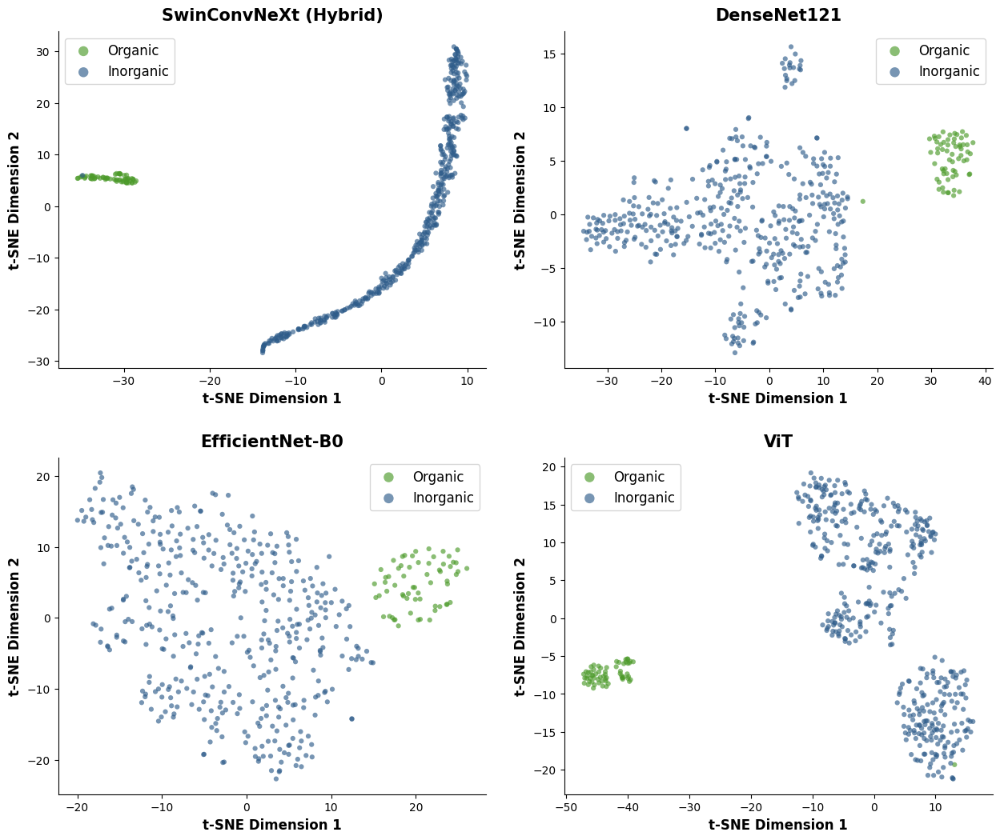


✅ Selesai! Cek Google Drive folder TA/file_pth/


In [ ]:
from sklearn.manifold import TSNE
import numpy as np
import matplotlib.pyplot as plt

def extract_features_swin(model, loader, max_samples=500):
    feats, labels = [], []
    with torch.no_grad():
        for imgs, lbl in loader:
            imgs = imgs.to(device)
            swin_feat = model.swin.forward_features(imgs)
            if swin_feat.dim() == 4:
                swin_feat = swin_feat.permute(0, 3, 1, 2)
            convnext_feat = model.convnext.forward_features(imgs)
            swin_out = model.swin_proj(swin_feat)
            convnext_out = model.convnext_proj(convnext_feat)
            fused = model.fusion(torch.cat([swin_out, convnext_out], dim=1))
            feats.append(fused.cpu().numpy())
            labels.append(lbl.numpy())
            if sum(len(x) for x in feats) >= max_samples: break
    return np.concatenate(feats)[:max_samples], np.concatenate(labels)[:max_samples]

def extract_features_densenet(model, loader, max_samples=500):
    import torch.nn.functional as F
    feats, labels = [], []
    with torch.no_grad():
        for imgs, lbl in loader:
            f = model.features(imgs.to(device))
            f = F.adaptive_avg_pool2d(f, (1,1))
            f = torch.flatten(f, 1)
            feats.append(f.cpu().numpy())
            labels.append(lbl.numpy())
            if sum(len(x) for x in feats) >= max_samples: break
    return np.concatenate(feats)[:max_samples], np.concatenate(labels)[:max_samples]

def extract_features_efficientnet(model, loader, max_samples=500):
    feats, labels = [], []
    with torch.no_grad():
        for imgs, lbl in loader:
            f = model.features(imgs.to(device))
            f = model.avgpool(f)
            f = torch.flatten(f, 1)
            feats.append(f.cpu().numpy())
            labels.append(lbl.numpy())
            if sum(len(x) for x in feats) >= max_samples: break
    return np.concatenate(feats)[:max_samples], np.concatenate(labels)[:max_samples]

def extract_features_vit(model, loader, max_samples=500):
    feats, labels = [], []
    with torch.no_grad():
        for imgs, lbl in loader:
            f = model.forward_features(imgs.to(device))
            f = f[:, 0, :]
            feats.append(f.cpu().numpy())
            labels.append(lbl.numpy())
            if sum(len(x) for x in feats) >= max_samples: break
    return np.concatenate(feats)[:max_samples], np.concatenate(labels)[:max_samples]

print("Extracting features...")
print("SwinConvNeXt...", end=" ")
feats_swin,  lbls_swin  = extract_features_swin(model_swin, test_loader)
print("✅")
print("DenseNet121...", end=" ")
feats_dense, lbls_dense = extract_features_densenet(model_densenet, test_loader)
print("✅")
print("EfficientNet-B0...", end=" ")
feats_eff,   lbls_eff   = extract_features_efficientnet(model_efficientnet, test_loader)
print("✅")
print("ViT...", end=" ")
feats_vit,   lbls_vit   = extract_features_vit(model_vit, test_loader)
print("✅")

print("\nRunning t-SNE (1-3 menit per model)...")
def run_tsne(feats):
    return TSNE(n_components=2, perplexity=40, n_iter=1200,
                random_state=42, verbose=0).fit_transform(feats)

print("SwinConvNeXt...", end=" ", flush=True); emb_swin  = run_tsne(feats_swin);  print("✅")
print("DenseNet121...", end=" ", flush=True);  emb_dense = run_tsne(feats_dense); print("✅")
print("EfficientNet-B0...", end=" ", flush=True); emb_eff = run_tsne(feats_eff);  print("✅")
print("ViT...", end=" ", flush=True);          emb_vit   = run_tsne(feats_vit);   print("✅")

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
axes = axes.flatten()
results = [
    ("SwinConvNeXt (Hybrid)", emb_swin,  lbls_swin),
    ("DenseNet121",           emb_dense, lbls_dense),
    ("EfficientNet-B0",       emb_eff,   lbls_eff),
    ("ViT",                   emb_vit,   lbls_vit),
]
colors = {0: "#4C9A2A", 1: "#2E5C8A"}
names  = {0: "Organic", 1: "Inorganic"}

for ax, (name, emb, lbls) in zip(axes, results):
    for cls in [0, 1]:
        mask = lbls == cls
        ax.scatter(emb[mask,0], emb[mask,1], c=colors[cls],
                   label=names[cls], alpha=0.65, s=20, edgecolors="none")
    ax.set_title(name, fontsize=15, fontweight="bold", pad=10)
    ax.set_xlabel("t-SNE Dimension 1", fontsize=12, fontweight="bold")
    ax.set_ylabel("t-SNE Dimension 2", fontsize=12, fontweight="bold")
    ax.legend(fontsize=12, markerscale=2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.tight_layout(pad=2.5)
plt.savefig("/content/drive/MyDrive/TA/file_pth/Fig_tSNE_all_models.png",
            dpi=300, bbox_inches="tight")
plt.show()
print("\n✅ Selesai! Cek Google Drive folder TA/file_pth/")

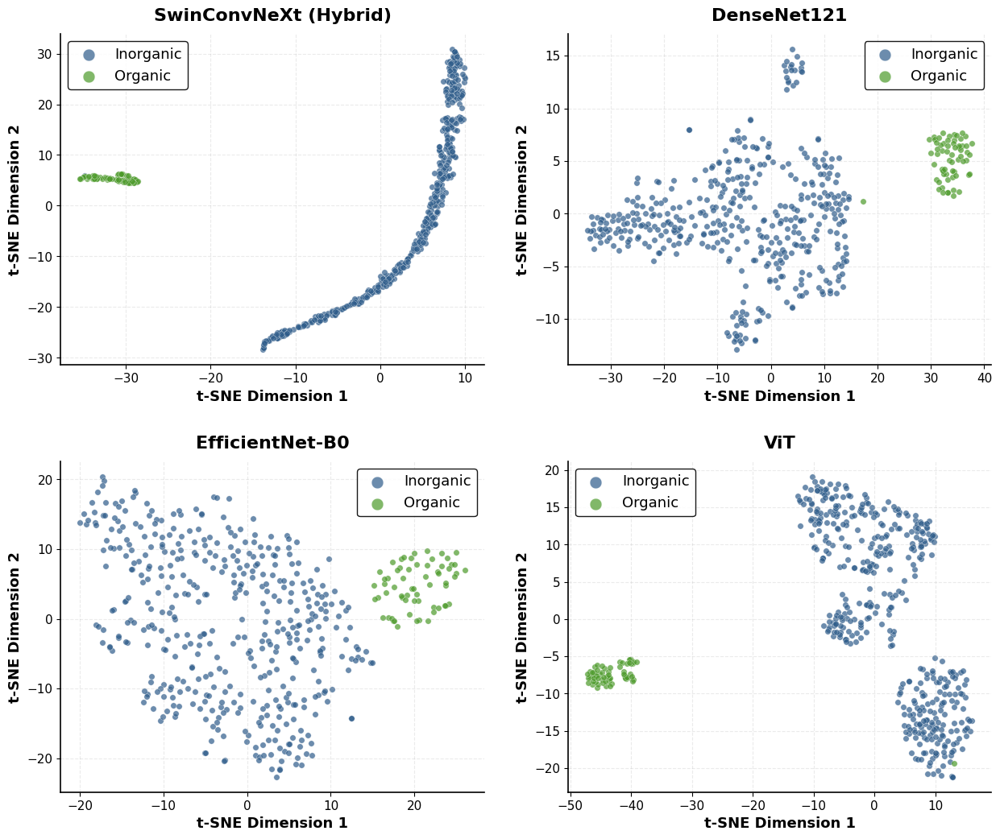

✅ Saved HQ: /content/drive/MyDrive/TA/file_pth/Fig_tSNE_HQ.png


In [ ]:
"""
Jalankan cell ini di Colab setelah cell t-SNE selesai
(variabel emb_swin, emb_dense, emb_eff, emb_vit, lbls_* masih ada di memory)
Ini menghasilkan versi HQ 600 DPI untuk paper
"""

import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np

plt.rcParams.update({"font.family": "DejaVu Sans"})

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
axes = axes.flatten()

results = [
    ("SwinConvNeXt (Hybrid)", emb_swin,  lbls_swin),
    ("DenseNet121",           emb_dense, lbls_dense),
    ("EfficientNet-B0",       emb_eff,   lbls_eff),
    ("ViT",                   emb_vit,   lbls_vit),
]

colors = {0: "#4C9A2A", 1: "#2E5C8A"}
names  = {0: "Organic", 1: "Inorganic"}

for ax, (name, emb, lbls) in zip(axes, results):
    for cls in [1, 0]:   # plot inorganic dulu agar organic di atas
        mask = lbls == cls
        ax.scatter(emb[mask, 0], emb[mask, 1],
                   c=colors[cls], label=names[cls],
                   alpha=0.70, s=28,
                   edgecolors="white", linewidths=0.3)

    ax.set_title(name, fontsize=16, fontweight="bold", pad=12)
    ax.set_xlabel("t-SNE Dimension 1", fontsize=13, fontweight="bold")
    ax.set_ylabel("t-SNE Dimension 2", fontsize=13, fontweight="bold")
    ax.tick_params(labelsize=11)

    leg = ax.legend(fontsize=13, markerscale=2.0, frameon=True,
                    edgecolor="black", framealpha=0.9)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.2)
    ax.spines["bottom"].set_linewidth(1.2)
    ax.grid(True, linestyle="--", alpha=0.25)

fig.tight_layout(pad=2.8)

# Simpan ke Drive
out = "/content/drive/MyDrive/TA/file_pth/Fig_tSNE_HQ.png"
fig.savefig(out, dpi=600, bbox_inches="tight")
plt.show()
print(f"✅ Saved HQ: {out}")

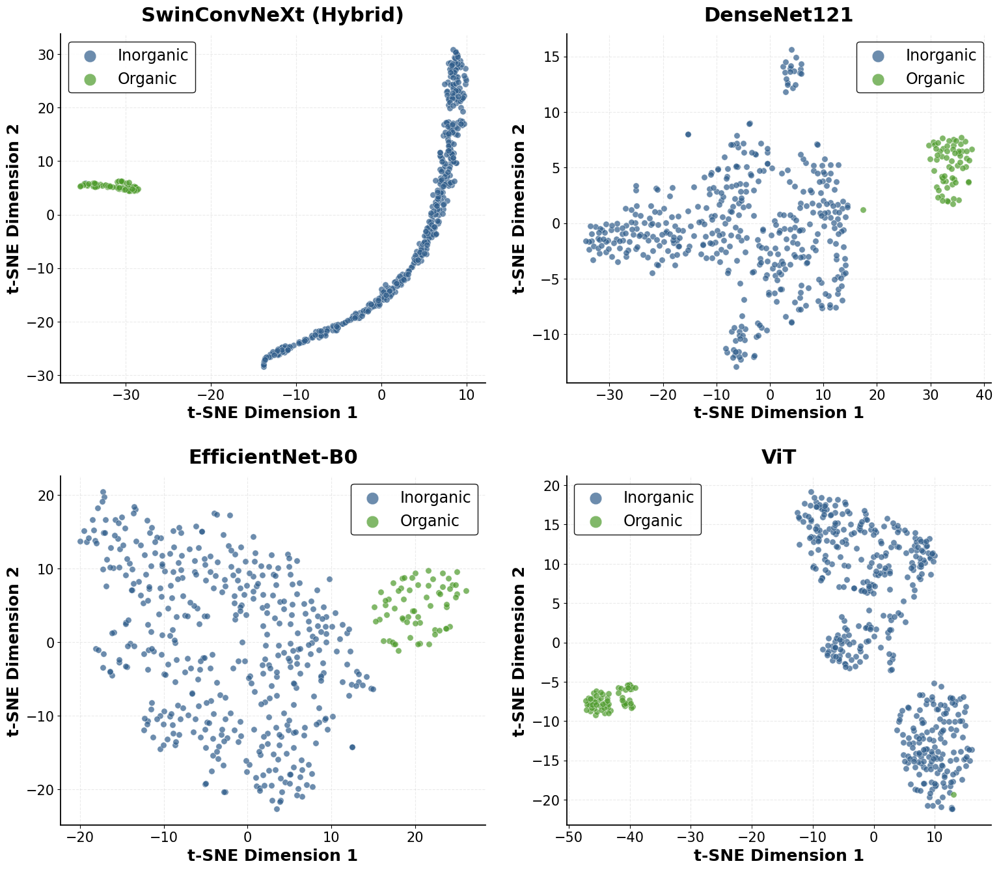

✅ Saved: /content/drive/MyDrive/TA/file_pth/Fig_tSNE_HQ_v2.png


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
axes = axes.flatten()
results = [
    ("SwinConvNeXt (Hybrid)", emb_swin,  lbls_swin),
    ("DenseNet121",           emb_dense, lbls_dense),
    ("EfficientNet-B0",       emb_eff,   lbls_eff),
    ("ViT",                   emb_vit,   lbls_vit),
]
colors = {0: "#4C9A2A", 1: "#2E5C8A"}
names  = {0: "Organic", 1: "Inorganic"}

for ax, (name, emb, lbls) in zip(axes, results):
    for cls in [1, 0]:
        mask = lbls == cls
        ax.scatter(emb[mask,0], emb[mask,1], c=colors[cls],
                   label=names[cls], alpha=0.70, s=45,
                   edgecolors="white", linewidths=0.4)
    ax.set_title(name, fontsize=22, fontweight="bold", pad=14)
    ax.set_xlabel("t-SNE Dimension 1", fontsize=18, fontweight="bold")
    ax.set_ylabel("t-SNE Dimension 2", fontsize=18, fontweight="bold")
    ax.tick_params(labelsize=15)
    ax.legend(fontsize=17, markerscale=2.0, frameon=True,
              edgecolor="black", framealpha=0.9)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.3)
    ax.spines["bottom"].set_linewidth(1.3)
    ax.grid(True, linestyle="--", alpha=0.25)

fig.tight_layout(pad=3.0)
out = "/content/drive/MyDrive/TA/file_pth/Fig_tSNE_HQ_v2.png"
fig.savefig(out, dpi=300, bbox_inches="tight")
plt.show()
print(f"✅ Saved: {out}")

In [ ]:
from statsmodels.stats.contingency_tables import mcnemar
import numpy as np

# Kumpulkan prediksi semua model di test set
def get_preds(model, loader):
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, lbls in loader:
            out = model(imgs.to(device))
            preds = out.argmax(dim=1).cpu().numpy()
            all_preds.append(preds)
            all_labels.append(lbls.numpy())
    return np.concatenate(all_preds), np.concatenate(all_labels)

print("Collecting predictions...")
preds_swin,  true_labels = get_preds(model_swin, test_loader)
preds_dense, _           = get_preds(model_densenet, test_loader)
preds_eff,   _           = get_preds(model_efficientnet, test_loader)
preds_vit,   _           = get_preds(model_vit, test_loader)

def mcnemar_test(preds_a, preds_b, true_labels, name_a, name_b):
    correct_a = (preds_a == true_labels)
    correct_b = (preds_b == true_labels)
    # Contingency table
    b = np.sum(correct_a & ~correct_b)   # A benar, B salah
    c = np.sum(~correct_a & correct_b)   # A salah, B benar
    table = [[0, b], [c, 0]]
    result = mcnemar(table, exact=False, correction=True)
    sig = "✅ Signifikan" if result.pvalue < 0.05 else "❌ Tidak signifikan"
    print(f"{name_a} vs {name_b}: p-value = {result.pvalue:.4f} → {sig}")
    return result.pvalue

print("\n=== McNemar's Test Results ===")
p1 = mcnemar_test(preds_swin, preds_vit,   true_labels, "SwinConvNeXt", "ViT")
p2 = mcnemar_test(preds_swin, preds_dense, true_labels, "SwinConvNeXt", "DenseNet121")
p3 = mcnemar_test(preds_swin, preds_eff,   true_labels, "SwinConvNeXt", "EfficientNet-B0")
p4 = mcnemar_test(preds_eff,  preds_dense, true_labels, "EfficientNet-B0", "DenseNet121")


=== McNemar's Test Results ===
SwinConvNeXt vs ViT: p-value = 0.8312 → ❌ Tidak signifikan
SwinConvNeXt vs DenseNet121: p-value = 0.2113 → ❌ Tidak signifikan
SwinConvNeXt vs EfficientNet-B0: p-value = 0.0265 → ✅ Signifikan
EfficientNet-B0 vs DenseNet121: p-value = 0.5050 → ❌ Tidak signifikan


In [ ]:
import os

# Cari semua file .pth di Google Drive
print("Mencari file .pth di Google Drive...")
for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for f in files:
        if f.endswith('.pth'):
            print(os.path.join(root, f))

Mencari file .pth di Google Drive...


In [ ]:
# Ganti sesuai hasil pencarian di atas
MODEL_DIR = '/content/drive/MyDrive/TA/dataset'  # <-- GANTI INI

# Verifikasi
for nama, file in {
    'SwinConvNeXt'   : 'best_swinconvnext.pth',
    'DenseNet121'    : 'best_densenet121.pth',
    'EfficientNet-B0': 'best_efficientnet_b0.pth',
    'ViT'            : 'best_vit.pth'
}.items():
    path = os.path.join(MODEL_DIR, file)
    print(f"{nama:20s}: {'✅ Ada' if os.path.exists(path) else '❌ Tidak ditemukan'} → {path}")

SwinConvNeXt        : ❌ Tidak ditemukan → /content/drive/MyDrive/TA/dataset/best_swinconvnext.pth
DenseNet121         : ❌ Tidak ditemukan → /content/drive/MyDrive/TA/dataset/best_densenet121.pth
EfficientNet-B0     : ❌ Tidak ditemukan → /content/drive/MyDrive/TA/dataset/best_efficientnet_b0.pth
ViT                 : ❌ Tidak ditemukan → /content/drive/MyDrive/TA/dataset/best_vit.pth


In [ ]:
import os

# Cell A: Load semua model dari Drive

# Correct MODEL_DIR to point to the actual saved model location
MODEL_DIR = '/content/drive/MyDrive/TA/dataset/archive (2).zip'

# Load SwinConvNeXt
model_swin = SwinConvNeXt(num_classes=2, dropout_rate=0.3).to(device)
model_swin.load_state_dict(torch.load(
    os.path.join(MODEL_DIR, 'best_swinconvnext.pth'),
    map_location=device
))
model_swin.eval()
print("✅ SwinConvNeXt loaded!")

# Load DenseNet121
model_densenet = create_densenet121().to(device)
model_densenet.load_state_dict(torch.load(
    os.path.join(MODEL_DIR, 'best_densenet121.pth'),
    map_location=device
))
model_densenet.eval()
print("✅ DenseNet121 loaded!")

# Load EfficientNet-B0
model_efficientnet = create_efficientnet_b0().to(device)
model_efficientnet.load_state_dict(torch.load(
    os.path.join(MODEL_DIR, 'best_efficientnet_b0.pth'),
    map_location=device
))
model_efficientnet.eval()
print("✅ EfficientNet-B0 loaded!")

# Load ViT
model_vit = create_vit().to(device)
model_vit.load_state_dict(torch.load(
    os.path.join(MODEL_DIR, 'best_vit.pth'),
    map_location=device
))
model_vit.eval()
print("✅ ViT loaded!")

# Definisikan all_models
all_models = {
    'SwinConvNeXt'   : model_swin,
    'DenseNet121'    : model_densenet,
    'EfficientNet-B0': model_efficientnet,
    'ViT'            : model_vit
}

print("\n✅ Semua model berhasil di-load!")

NotADirectoryError: [Errno 20] Not a directory: '/content/drive/MyDrive/TA/dataset/archive (2).zip/best_swinconvnext.pth'

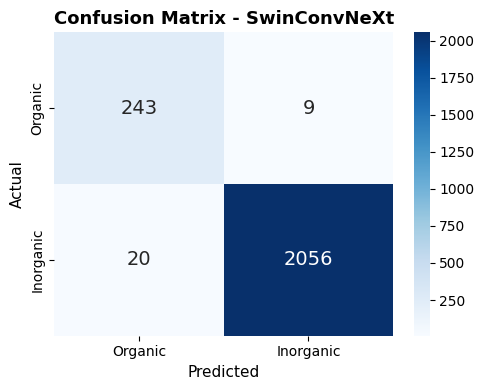

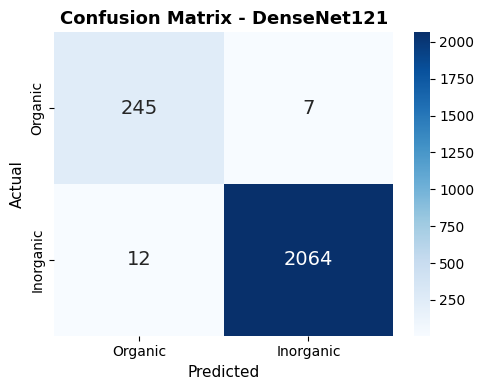

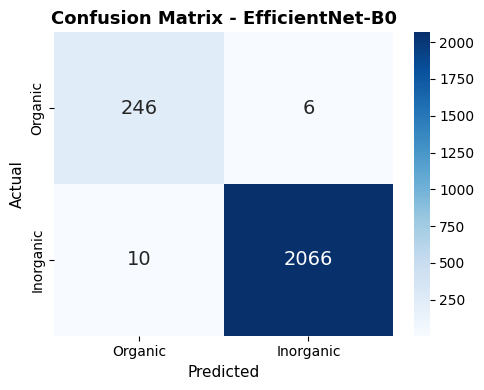

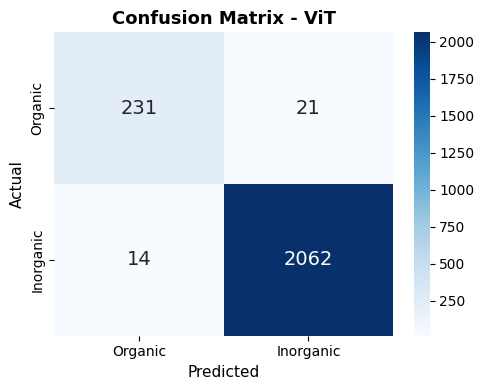

In [ ]:
# Cell B: Generate confusion matrix terpisah per model

criterion_eval = nn.CrossEntropyLoss(weight=class_weight_tensor)

# Update PLOT_DIR ke folder yang benar
PLOT_DIR = '/content/drive/MyDrive/revisi_TA_jul'

for model_name, model in all_models.items():
    metrics = evaluate(model, test_loader, criterion_eval, device)
    cm = confusion_matrix(metrics['labels'], metrics['preds'])

    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Organic', 'Inorganic'],
        yticklabels=['Organic', 'Inorganic'],
        ax=ax,
        annot_kws={'size': 14}
    )
    ax.set_title(f'Confusion Matrix - {model_name}',
                 fontsize=13, fontweight='bold')
    ax.set_xlabel('Predicted', fontsize=11)
    ax.set_ylabel('Actual', fontsize=11)

    plt.tight_layout()

In [ ]:
# Cell 14: Training SwinConvNeXt + Simpan ke Google Drive

model_swin = SwinConvNeXt(num_classes=2, dropout_rate=0.3).to(device)

model_swin, history_swin = train_model(
    model=model_swin,
    model_name='SwinConvNeXt',
    train_loader=train_loader,
    val_loader=val_loader,
    class_weight_tensor=class_weight_tensor,
    device=device,
    num_epochs=75,
    patience=10,
    lr=1e-4
)

# Simpan model ke Google Drive
save_path = os.path.join(MODEL_DIR, 'best_swinconvnext.pth')
torch.save(model_swin.state_dict(), save_path)
print(f"✅ Model SwinConvNeXt tersimpan di: {save_path}")


TRAINING: SwinConvNeXt
Epoch [  1/75] | Train Loss: 0.1115 Acc: 0.9444 | Val Loss: 0.1315 Acc: 0.9790 F1: 0.9793 MacroF1: 0.9474
Epoch [  5/75] | Train Loss: 0.0530 Acc: 0.9816 | Val Loss: 0.2024 Acc: 0.9841 F1: 0.9840 MacroF1: 0.9580
Epoch [ 10/75] | Train Loss: 0.0436 Acc: 0.9862 | Val Loss: 0.1897 Acc: 0.9841 F1: 0.9841 MacroF1: 0.9591
Epoch [ 15/75] | Train Loss: 0.0261 Acc: 0.9924 | Val Loss: 0.1941 Acc: 0.9845 F1: 0.9845 MacroF1: 0.9598
Epoch [ 20/75] | Train Loss: 0.0264 Acc: 0.9913 | Val Loss: 0.0841 Acc: 0.9897 F1: 0.9897 MacroF1: 0.9735
Epoch [ 25/75] | Train Loss: 0.0209 Acc: 0.9949 | Val Loss: 0.0677 Acc: 0.9897 F1: 0.9898 MacroF1: 0.9738

Early stopping di epoch 26
Best Macro F1: 0.9761

Training selesai! Best Macro F1: 0.9761
✅ Model SwinConvNeXt tersimpan di: /content/drive/MyDrive/TA/hasil_training/models/best_swinconvnext.pth


In [ ]:
# Cek apakah history_swin masih ada di memory
try:
    print(f"history_swin ada!")
    print(f"Jumlah epoch   : {len(history_swin['train_loss'])}")
    print(f"Best val acc   : {max(history_swin['val_acc']):.4f}")
    print(f"Best Macro F1  : {max(history_swin['val_macro_f1']):.4f}")
except NameError:
    print("❌ history_swin tidak ada di memory!")
    print("Perlu retrain SwinConvNeXt dulu dari Cell 14")

history_swin ada!
Jumlah epoch   : 26
Best val acc   : 0.9905
Best Macro F1  : 0.9761


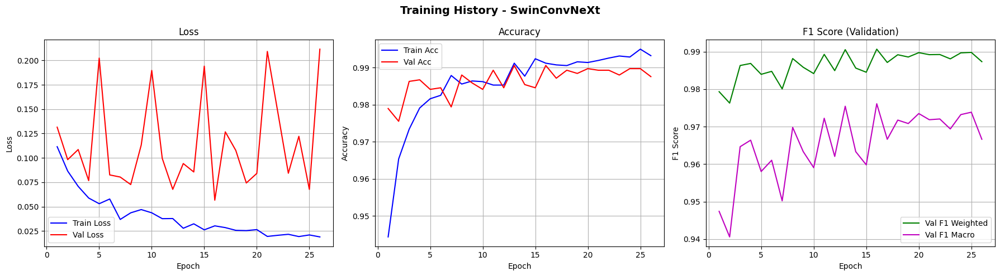

✅ Plot tersimpan di: /content/drive/MyDrive/TA/hasil_training/plots/history_swinconvnext.png


In [ ]:
# Cell 15: Plot history + Simpan ke Google Drive

def plot_history(history, model_name, save_dir):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f'Training History - {model_name}',
                 fontsize=14, fontweight='bold')

    epochs = range(1, len(history['train_loss']) + 1)

    axes[0].plot(epochs, history['train_loss'], 'b-', label='Train Loss')
    axes[0].plot(epochs, history['val_loss'],   'r-', label='Val Loss')
    axes[0].set_title('Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(epochs, history['train_acc'], 'b-', label='Train Acc')
    axes[1].plot(epochs, history['val_acc'],   'r-', label='Val Acc')
    axes[1].set_title('Accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend()
    axes[1].grid(True)

    axes[2].plot(epochs, history['val_f1'],       'g-', label='Val F1 Weighted')
    axes[2].plot(epochs, history['val_macro_f1'], 'm-', label='Val F1 Macro')
    axes[2].set_title('F1 Score (Validation)')
    axes[2].set_xlabel('Epoch')
    axes[2].set_ylabel('F1 Score')
    axes[2].legend()
    axes[2].grid(True)

    plt.tight_layout()

    # Simpan ke Google Drive
    filename = f'history_{model_name.lower().replace(" ", "_")}.png'
    save_path = os.path.join(save_dir, filename)
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"✅ Plot tersimpan di: {save_path}")

plot_history(history_swin, 'SwinConvNeXt', PLOT_DIR)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=DenseNet121_Weights.IMAGENET1K_V1`. You can also use `weights=DenseNet121_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)



TRAINING: DenseNet121
Epoch [  1/75] | Train Loss: 0.1041 Acc: 0.9260 | Val Loss: 0.1152 Acc: 0.9738 F1: 0.9744 MacroF1: 0.9354
Epoch [  5/75] | Train Loss: 0.0437 Acc: 0.9772 | Val Loss: 0.1148 Acc: 0.9867 F1: 0.9867 MacroF1: 0.9656
Epoch [ 10/75] | Train Loss: 0.0319 Acc: 0.9856 | Val Loss: 0.1164 Acc: 0.9841 F1: 0.9844 MacroF1: 0.9603
Epoch [ 15/75] | Train Loss: 0.0287 Acc: 0.9885 | Val Loss: 0.1325 Acc: 0.9910 F1: 0.9909 MacroF1: 0.9763
Epoch [ 20/75] | Train Loss: 0.0150 Acc: 0.9928 | Val Loss: 0.1723 Acc: 0.9875 F1: 0.9875 MacroF1: 0.9675
Epoch [ 25/75] | Train Loss: 0.0094 Acc: 0.9952 | Val Loss: 0.0858 Acc: 0.9901 F1: 0.9901 MacroF1: 0.9745

Early stopping di epoch 26
Best Macro F1: 0.9766

Training selesai! Best Macro F1: 0.9766
✅ Model DenseNet121 tersimpan di: /content/drive/MyDrive/TA/hasil_training/models/best_densenet121.pth


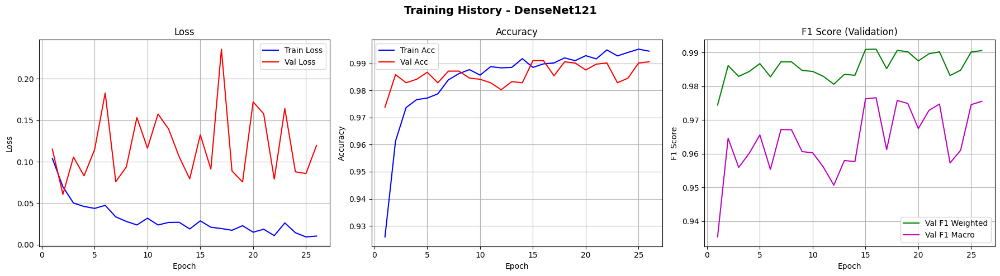

✅ Plot tersimpan di: /content/drive/MyDrive/TA/hasil_training/plots/history_densenet121.png


In [ ]:
# Cell 16: Training DenseNet121

model_densenet = create_densenet121().to(device)

model_densenet, history_densenet = train_model(
    model=model_densenet,
    model_name='DenseNet121',
    train_loader=train_loader,
    val_loader=val_loader,
    class_weight_tensor=class_weight_tensor,
    device=device,
    num_epochs=75,
    patience=10,
    lr=1e-4
)

# Simpan ke Drive
save_path = os.path.join(MODEL_DIR, 'best_densenet121.pth')
torch.save(model_densenet.state_dict(), save_path)
print(f"✅ Model DenseNet121 tersimpan di: {save_path}")

plot_history(history_densenet, 'DenseNet121', PLOT_DIR)

In [ ]:
# Cek history_densenet
try:
    print(f"history_densenet ada!")
    print(f"Jumlah epoch  : {len(history_densenet['train_loss'])}")
    print(f"Best val acc  : {max(history_densenet['val_acc']):.4f}")
    print(f"Best Macro F1 : {max(history_densenet['val_macro_f1']):.4f}")
except NameError:
    print("❌ history_densenet tidak ada di memory!")
    print("Plot tidak bisa dijalankan, perlu retrain DenseNet121")

history_densenet ada!
Jumlah epoch  : 26
Best val acc  : 0.9910
Best Macro F1 : 0.9766



TRAINING: EfficientNet-B0


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Epoch [  1/75] | Train Loss: 0.1186 Acc: 0.9006 | Val Loss: 0.0560 Acc: 0.9811 F1: 0.9816 MacroF1: 0.9539
Epoch [  5/75] | Train Loss: 0.0354 Acc: 0.9815 | Val Loss: 0.0573 Acc: 0.9918 F1: 0.9918 MacroF1: 0.9788
Epoch [ 10/75] | Train Loss: 0.0183 Acc: 0.9927 | Val Loss: 0.2045 Acc: 0.9858 F1: 0.9855 MacroF1: 0.9615
Epoch [ 15/75] | Train Loss: 0.0156 Acc: 0.9937 | Val Loss: 0.1155 Acc: 0.9905 F1: 0.9904 MacroF1: 0.9748

Early stopping di epoch 16
Best Macro F1: 0.9843

Training selesai! Best Macro F1: 0.9843
✅ Model EfficientNet-B0 tersimpan di: /content/drive/MyDrive/TA/hasil_training/models/best_efficientnet_b0.pth


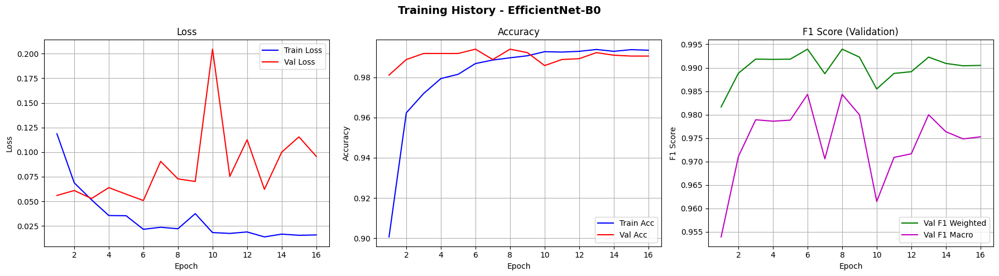

✅ Plot tersimpan di: /content/drive/MyDrive/TA/hasil_training/plots/history_efficientnet-b0.png


In [ ]:
# Cell 17: Training EfficientNet-B0

model_efficientnet = create_efficientnet_b0().to(device)

model_efficientnet, history_efficientnet = train_model(
    model=model_efficientnet,
    model_name='EfficientNet-B0',
    train_loader=train_loader,
    val_loader=val_loader,
    class_weight_tensor=class_weight_tensor,
    device=device,
    num_epochs=75,
    patience=10,
    lr=1e-4
)

# Simpan ke Drive
save_path = os.path.join(MODEL_DIR, 'best_efficientnet_b0.pth')
torch.save(model_efficientnet.state_dict(), save_path)
print(f"✅ Model EfficientNet-B0 tersimpan di: {save_path}")

plot_history(history_efficientnet, 'EfficientNet-B0', PLOT_DIR)


TRAINING: ViT
Epoch [  1/75] | Train Loss: 0.1048 Acc: 0.9380 | Val Loss: 0.0680 Acc: 0.9721 F1: 0.9733 MacroF1: 0.9339
Epoch [  5/75] | Train Loss: 0.0420 Acc: 0.9815 | Val Loss: 0.0766 Acc: 0.9867 F1: 0.9868 MacroF1: 0.9662
Epoch [ 10/75] | Train Loss: 0.0315 Acc: 0.9866 | Val Loss: 0.0921 Acc: 0.9850 F1: 0.9851 MacroF1: 0.9615
Epoch [ 15/75] | Train Loss: 0.0261 Acc: 0.9893 | Val Loss: 0.1573 Acc: 0.9875 F1: 0.9875 MacroF1: 0.9673

Early stopping di epoch 16
Best Macro F1: 0.9709

Training selesai! Best Macro F1: 0.9709
✅ Model ViT tersimpan di: /content/drive/MyDrive/TA/hasil_training/models/best_vit.pth


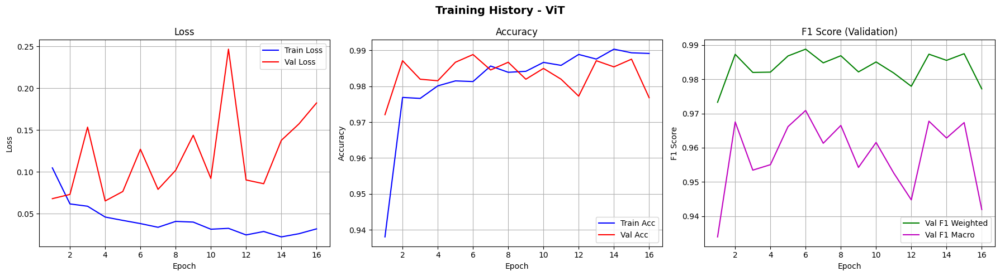

✅ Plot tersimpan di: /content/drive/MyDrive/TA/hasil_training/plots/history_vit.png


In [ ]:
# Cell 18: Training ViT

model_vit = create_vit().to(device)

model_vit, history_vit = train_model(
    model=model_vit,
    model_name='ViT',
    train_loader=train_loader,
    val_loader=val_loader,
    class_weight_tensor=class_weight_tensor,
    device=device,
    num_epochs=75,
    patience=10,
    lr=1e-4
)

# Simpan ke Drive
save_path = os.path.join(MODEL_DIR, 'best_vit.pth')
torch.save(model_vit.state_dict(), save_path)
print(f"✅ Model ViT tersimpan di: {save_path}")

plot_history(history_vit, 'ViT', PLOT_DIR)

In [ ]:
# Cell 19: Evaluasi final semua model di test set + simpan hasil

criterion_eval = nn.CrossEntropyLoss(weight=class_weight_tensor)

all_models = {
    'SwinConvNeXt' : model_swin,
    'DenseNet121'  : model_densenet,
    'EfficientNet-B0': model_efficientnet,
    'ViT'          : model_vit
}

results = {}

print("=" * 60)
print("EVALUASI FINAL DI TEST SET")
print("=" * 60)

for model_name, model in all_models.items():
    metrics = evaluate(model, test_loader, criterion_eval, device)
    results[model_name] = metrics

    print(f"\n{model_name}:")
    print(f"  Accuracy  : {metrics['accuracy']*100:.2f}%")
    print(f"  Precision : {metrics['precision']*100:.2f}%")
    print(f"  Recall    : {metrics['recall']*100:.2f}%")
    print(f"  F1 Score  : {metrics['f1']*100:.2f}%")
    print(f"  Macro F1  : {metrics['macro_f1']*100:.2f}%")
    print(f"  ROC-AUC   : {metrics['auc']*100:.2f}%")

# Simpan hasil ke CSV di Google Drive
results_df = pd.DataFrame({
    name: {
        'Accuracy'  : f"{m['accuracy']*100:.2f}",
        'Precision' : f"{m['precision']*100:.2f}",
        'Recall'    : f"{m['recall']*100:.2f}",
        'F1 Score'  : f"{m['f1']*100:.2f}",
        'Macro F1'  : f"{m['macro_f1']*100:.2f}",
        'ROC-AUC'   : f"{m['auc']*100:.2f}",
    }
    for name, m in results.items()
}).T

csv_path = os.path.join(RESULT_DIR, 'hasil_evaluasi_semua_model.csv')
results_df.to_csv(csv_path)
print(f"\n✅ Hasil evaluasi tersimpan di: {csv_path}")
print()
print(results_df.to_string())

EVALUASI FINAL DI TEST SET

SwinConvNeXt:
  Accuracy  : 98.75%
  Precision : 98.79%
  Recall    : 98.75%
  F1 Score  : 98.77%
  Macro F1  : 96.83%
  ROC-AUC   : 99.74%

DenseNet121:
  Accuracy  : 99.18%
  Precision : 99.19%
  Recall    : 99.18%
  F1 Score  : 99.19%
  Macro F1  : 97.90%
  ROC-AUC   : 99.88%

EfficientNet-B0:
  Accuracy  : 99.31%
  Precision : 99.32%
  Recall    : 99.31%
  F1 Score  : 99.32%
  Macro F1  : 98.23%
  ROC-AUC   : 99.95%

ViT:
  Accuracy  : 98.50%
  Precision : 98.48%
  Recall    : 98.50%
  F1 Score  : 98.49%
  Macro F1  : 96.06%
  ROC-AUC   : 99.49%

✅ Hasil evaluasi tersimpan di: /content/drive/MyDrive/TA/hasil_training/results/hasil_evaluasi_semua_model.csv

                Accuracy Precision Recall F1 Score Macro F1 ROC-AUC
SwinConvNeXt       98.75     98.79  98.75    98.77    96.83   99.74
DenseNet121        99.18     99.19  99.18    99.19    97.90   99.88
EfficientNet-B0    99.31     99.32  99.31    99.32    98.23   99.95
ViT                98.50     98

In [ ]:
# Cell 20: Per-class performance semua model (dengan Accuracy)

print("=" * 80)
print("PER-CLASS PERFORMANCE SEMUA MODEL")
print("=" * 80)

per_class_results = {}

for model_name, model in all_models.items():
    metrics = evaluate(model, test_loader, criterion_eval, device)

    y_true = metrics['labels']
    y_pred = metrics['preds']

    # Hitung per-class metrics
    report = classification_report(
        y_true, y_pred,
        target_names=['Organic', 'Inorganic'],
        output_dict=True,
        zero_division=0
    )

    # Hitung per-class accuracy manual
    cm = confusion_matrix(y_true, y_pred)

    # Organic  : TP=cm[0,0], TN=cm[1,1], FP=cm[1,0], FN=cm[0,1]
    acc_organic   = cm[0,0] / cm[0].sum() * 100  # Recall = per-class acc
    acc_inorganic = cm[1,1] / cm[1].sum() * 100

    per_class_results[model_name] = {
        'report'        : report,
        'acc_organic'   : acc_organic,
        'acc_inorganic' : acc_inorganic
    }

    print(f"\n{model_name}:")
    print(f"  {'Class':<12} {'Accuracy':>10} {'Precision':>10} "
          f"{'Recall':>10} {'F1-Score':>10} {'Images':>8}")
    print(f"  {'-'*62}")

    # Organic
    p_org  = report['Organic']['precision'] * 100
    r_org  = report['Organic']['recall'] * 100
    f1_org = report['Organic']['f1-score'] * 100
    s_org  = int(report['Organic']['support'])
    print(f"  {'Organic':<12} {acc_organic:>9.2f}% {p_org:>9.2f}% "
          f"{r_org:>9.2f}% {f1_org:>9.2f}% {s_org:>8}")

    # Inorganic
    p_ino  = report['Inorganic']['precision'] * 100
    r_ino  = report['Inorganic']['recall'] * 100
    f1_ino = report['Inorganic']['f1-score'] * 100
    s_ino  = int(report['Inorganic']['support'])
    print(f"  {'Inorganic':<12} {acc_inorganic:>9.2f}% {p_ino:>9.2f}% "
          f"{r_ino:>9.2f}% {f1_ino:>9.2f}% {s_ino:>8}")

print()
print("✅ Per-class performance selesai!")

PER-CLASS PERFORMANCE SEMUA MODEL

SwinConvNeXt:
  Class          Accuracy  Precision     Recall   F1-Score   Images
  --------------------------------------------------------------
  Organic          96.43%     92.40%     96.43%     94.37%      252
  Inorganic        99.04%     99.56%     99.04%     99.30%     2076

DenseNet121:
  Class          Accuracy  Precision     Recall   F1-Score   Images
  --------------------------------------------------------------
  Organic          97.22%     95.33%     97.22%     96.27%      252
  Inorganic        99.42%     99.66%     99.42%     99.54%     2076

EfficientNet-B0:
  Class          Accuracy  Precision     Recall   F1-Score   Images
  --------------------------------------------------------------
  Organic          97.62%     96.09%     97.62%     96.85%      252
  Inorganic        99.52%     99.71%     99.52%     99.61%     2076

ViT:
  Class          Accuracy  Precision     Recall   F1-Score   Images
  ------------------------------------

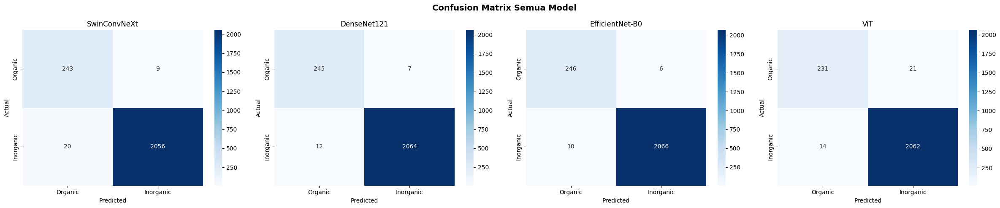

✅ Confusion matrix tersimpan di: /content/drive/MyDrive/TA/hasil_training/plots/confusion_matrix_semua_model.png


In [ ]:
# Cell 21: Confusion matrix semua model

fig, axes = plt.subplots(1, 4, figsize=(24, 5))
fig.suptitle('Confusion Matrix Semua Model',
             fontsize=14, fontweight='bold')

for idx, (model_name, model) in enumerate(all_models.items()):
    metrics = evaluate(model, test_loader, criterion_eval, device)

    cm = confusion_matrix(metrics['labels'], metrics['preds'])

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Organic', 'Inorganic'],
        yticklabels=['Organic', 'Inorganic'],
        ax=axes[idx]
    )
    axes[idx].set_title(model_name)
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')

plt.tight_layout()

# Simpan ke Drive
plot_path = os.path.join(PLOT_DIR, 'confusion_matrix_semua_model.png')
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Confusion matrix tersimpan di: {plot_path}")

In [ ]:
# Cell 22: Tabel ringkasan lengkap siap untuk paper

print("=" * 75)
print("TABLE II: OVERALL PERFORMANCE (Siap untuk Paper)")
print("=" * 75)

table2_data = []
for model_name, model in all_models.items():
    metrics = evaluate(model, test_loader, criterion_eval, device)
    table2_data.append({
        'Model'    : model_name,
        'Accuracy' : f"{metrics['accuracy']*100:.2f}%",
        'Precision': f"{metrics['precision']*100:.2f}%",
        'Recall'   : f"{metrics['recall']*100:.2f}%",
        'F1-Score' : f"{metrics['f1']*100:.2f}%",
        'Macro F1' : f"{metrics['macro_f1']*100:.2f}%",
        'ROC-AUC'  : f"{metrics['auc']*100:.2f}%",
    })

table2_df = pd.DataFrame(table2_data)
print(table2_df.to_string(index=False))

# ===============================================

print()
print("=" * 75)
print("TABLE III: PER-CLASS PERFORMANCE (Siap untuk Paper)")
print("=" * 75)

table3_data = []
for model_name, model in all_models.items():
    metrics  = evaluate(model, test_loader, criterion_eval, device)
    y_true   = metrics['labels']
    y_pred   = metrics['preds']
    report   = classification_report(
        y_true, y_pred,
        target_names=['Organic', 'Inorganic'],
        output_dict=True,
        zero_division=0
    )
    cm = confusion_matrix(y_true, y_pred)

    # Per-class accuracy
    acc_organic   = cm[0,0] / cm[0].sum() * 100
    acc_inorganic = cm[1,1] / cm[1].sum() * 100

    # Organic row
    table3_data.append({
        'Model'    : model_name,
        'Class'    : 'Organic',
        'Accuracy' : f"{acc_organic:.2f}%",
        'Precision': f"{report['Organic']['precision']*100:.2f}%",
        'Recall'   : f"{report['Organic']['recall']*100:.2f}%",
        'F1-Score' : f"{report['Organic']['f1-score']*100:.2f}%",
        'Images'   : int(report['Organic']['support'])
    })

    # Inorganic row
    table3_data.append({
        'Model'    : model_name,
        'Class'    : 'Inorganic',
        'Accuracy' : f"{acc_inorganic:.2f}%",
        'Precision': f"{report['Inorganic']['precision']*100:.2f}%",
        'Recall'   : f"{report['Inorganic']['recall']*100:.2f}%",
        'F1-Score' : f"{report['Inorganic']['f1-score']*100:.2f}%",
        'Images'   : int(report['Inorganic']['support'])
    })

table3_df = pd.DataFrame(table3_data)
print(table3_df.to_string(index=False))

# Simpan ke CSV
table2_path = os.path.join(RESULT_DIR, 'table2_overall_performance.csv')
table3_path = os.path.join(RESULT_DIR, 'table3_per_class_performance.csv')

table2_df.to_csv(table2_path, index=False)
table3_df.to_csv(table3_path, index=False)

print(f"\n✅ Table II tersimpan di: {table2_path}")
print(f"✅ Table III tersimpan di: {table3_path}")

TABLE II: OVERALL PERFORMANCE (Siap untuk Paper)
          Model Accuracy Precision Recall F1-Score Macro F1 ROC-AUC
   SwinConvNeXt   98.75%    98.79% 98.75%   98.77%   96.83%  99.74%
    DenseNet121   99.18%    99.19% 99.18%   99.19%   97.90%  99.88%
EfficientNet-B0   99.31%    99.32% 99.31%   99.32%   98.23%  99.95%
            ViT   98.50%    98.48% 98.50%   98.49%   96.06%  99.49%

TABLE III: PER-CLASS PERFORMANCE (Siap untuk Paper)
          Model     Class Accuracy Precision Recall F1-Score  Images
   SwinConvNeXt   Organic   96.43%    92.40% 96.43%   94.37%     252
   SwinConvNeXt Inorganic   99.04%    99.56% 99.04%   99.30%    2076
    DenseNet121   Organic   97.22%    95.33% 97.22%   96.27%     252
    DenseNet121 Inorganic   99.42%    99.66% 99.42%   99.54%    2076
EfficientNet-B0   Organic   97.62%    96.09% 97.62%   96.85%     252
EfficientNet-B0 Inorganic   99.52%    99.71% 99.52%   99.61%    2076
            ViT   Organic   91.67%    94.29% 91.67%   92.96%     252
      

In [ ]:
# Cell 23: Setup Grad-CAM

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
import numpy as np
import matplotlib.pyplot as plt
import torch

print("✅ Grad-CAM siap digunakan!")

✅ Grad-CAM siap digunakan!


In [ ]:
# Cell 24: Ambil sample gambar dari test set
# Ambil beberapa gambar Organic dan Inorganic

def get_sample_images(dataset, num_per_class=4):
    organic_samples   = []
    inorganic_samples = []

    for idx in range(len(dataset)):
        if len(organic_samples) >= num_per_class and \
           len(inorganic_samples) >= num_per_class:
            break

        img_path = dataset.df.iloc[idx]['path']
        label    = dataset.df.iloc[idx]['label']

        # Load gambar original (tanpa normalisasi untuk visualisasi)
        img_orig = Image.open(img_path).convert('RGB')
        img_orig = img_orig.resize((224, 224))
        img_np   = np.array(img_orig) / 255.0

        # Load gambar dengan transform (untuk input model)
        img_tensor = val_test_transform(img_orig)

        if label == 0 and len(organic_samples) < num_per_class:
            organic_samples.append({
                'path'      : img_path,
                'label'     : label,
                'img_np'    : img_np,
                'img_tensor': img_tensor
            })
        elif label == 1 and len(inorganic_samples) < num_per_class:
            inorganic_samples.append({
                'path'      : img_path,
                'label'     : label,
                'img_np'    : img_np,
                'img_tensor': img_tensor
            })

    return organic_samples, inorganic_samples

organic_samples, inorganic_samples = get_sample_images(test_dataset, num_per_class=4)

print(f"Organic samples   : {len(organic_samples)}")
print(f"Inorganic samples : {len(inorganic_samples)}")
print("✅ Sample gambar berhasil diambil!")

Organic samples   : 4
Inorganic samples : 4
✅ Sample gambar berhasil diambil!


In [ ]:
# Cell 25: Fungsi generate Grad-CAM untuk setiap model

def get_gradcam_target_layer(model, model_name):
    """Ambil target layer yang tepat untuk setiap model"""
    if model_name == 'SwinConvNeXt':
        # Layer terakhir ConvNeXt block
        return [model.convnext.stages[-1].blocks[-1].conv_dw]
    elif model_name == 'DenseNet121':
        return [model.features.denseblock4.denselayer16.conv2]
    elif model_name == 'EfficientNet-B0':
        return [model.features[-1][0]]
    elif model_name == 'ViT':
        return [model.blocks[-1].norm1]

def generate_gradcam(model, model_name, img_tensor, target_class):
    """Generate Grad-CAM visualization"""
    try:
        target_layer = get_gradcam_target_layer(model, model_name)

        cam = GradCAM(
            model=model,
            target_layers=target_layer
        )

        input_tensor = img_tensor.unsqueeze(0).to(device)
        targets      = [ClassifierOutputTarget(target_class)]

        grayscale_cam = cam(
            input_tensor=input_tensor,
            targets=targets
        )

        return grayscale_cam[0]

    except Exception as e:
        print(f"  Error pada {model_name}: {e}")
        return None

print("✅ Fungsi Grad-CAM berhasil didefinisikan!")

✅ Fungsi Grad-CAM berhasil didefinisikan!


Generating Grad-CAM untuk kelas Organic...
  Error pada ViT: Invalid grads shape.Shape of grads should be 4 (2D image) or 5 (3D image).
  Error pada ViT: Invalid grads shape.Shape of grads should be 4 (2D image) or 5 (3D image).
  Error pada ViT: Invalid grads shape.Shape of grads should be 4 (2D image) or 5 (3D image).
  Error pada ViT: Invalid grads shape.Shape of grads should be 4 (2D image) or 5 (3D image).


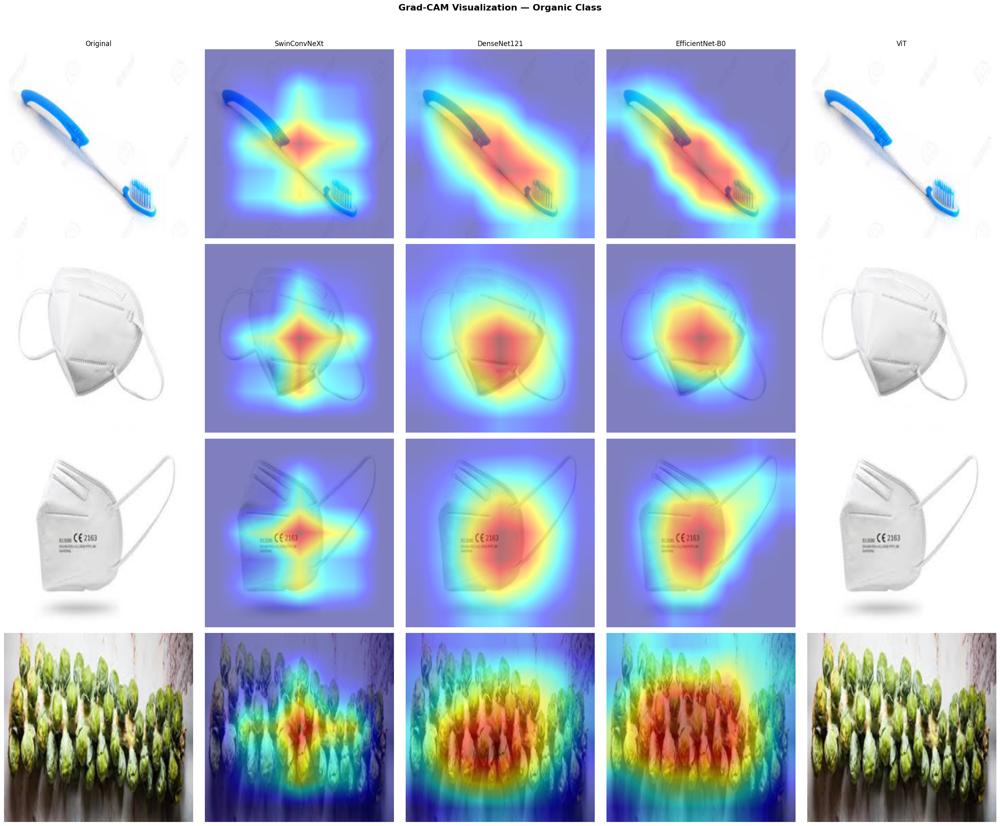

✅ Grad-CAM Organic tersimpan di: /content/drive/MyDrive/TA/hasil_training/plots/gradcam_organic.png


In [ ]:
# Cell 26: Visualisasi Grad-CAM semua model

def plot_gradcam_comparison(samples, class_name, class_idx, save_dir):
    """Plot Grad-CAM untuk semua model pada satu kelas"""

    model_list = {
        'SwinConvNeXt'   : model_swin,
        'DenseNet121'    : model_densenet,
        'EfficientNet-B0': model_efficientnet,
        'ViT'            : model_vit
    }

    n_samples = len(samples)
    n_models  = len(model_list)

    # n_samples baris, n_models+1 kolom (kolom pertama = original)
    fig, axes = plt.subplots(
        n_samples, n_models + 1,
        figsize=(5 * (n_models + 1), 5 * n_samples)
    )

    fig.suptitle(
        f'Grad-CAM Visualization — {class_name} Class',
        fontsize=16, fontweight='bold', y=1.02
    )

    for row, sample in enumerate(samples):
        img_np     = sample['img_np']
        img_tensor = sample['img_tensor']

        # Kolom pertama: gambar original
        axes[row, 0].imshow(img_np)
        axes[row, 0].set_title('Original' if row == 0 else '')
        axes[row, 0].axis('off')

        # Kolom berikutnya: Grad-CAM tiap model
        for col, (model_name, model) in enumerate(model_list.items()):
            cam_result = generate_gradcam(
                model, model_name, img_tensor, class_idx
            )

            if cam_result is not None:
                visualization = show_cam_on_image(
                    img_np.astype(np.float32),
                    cam_result,
                    use_rgb=True
                )
                axes[row, col + 1].imshow(visualization)
            else:
                axes[row, col + 1].imshow(img_np)

            axes[row, col + 1].set_title(
                model_name if row == 0 else ''
            )
            axes[row, col + 1].axis('off')

    plt.tight_layout()

    # Simpan ke Drive
    filename  = f'gradcam_{class_name.lower()}.png'
    save_path = os.path.join(save_dir, filename)
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"✅ Grad-CAM {class_name} tersimpan di: {save_path}")

# Generate untuk kelas Organic
print("Generating Grad-CAM untuk kelas Organic...")
plot_gradcam_comparison(
    samples    = organic_samples,
    class_name = 'Organic',
    class_idx  = 0,
    save_dir   = PLOT_DIR
)

Generating Grad-CAM untuk kelas Inorganic...
  Error pada ViT: Invalid grads shape.Shape of grads should be 4 (2D image) or 5 (3D image).
  Error pada ViT: Invalid grads shape.Shape of grads should be 4 (2D image) or 5 (3D image).
  Error pada ViT: Invalid grads shape.Shape of grads should be 4 (2D image) or 5 (3D image).
  Error pada ViT: Invalid grads shape.Shape of grads should be 4 (2D image) or 5 (3D image).


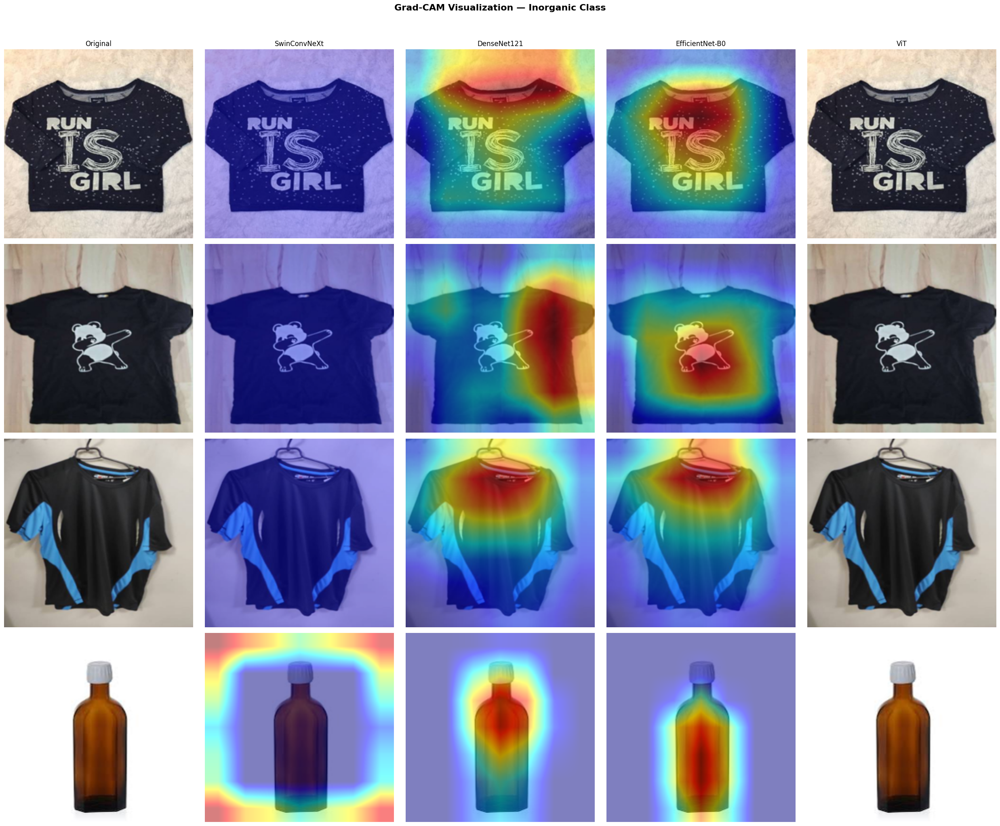

✅ Grad-CAM Inorganic tersimpan di: /content/drive/MyDrive/TA/hasil_training/plots/gradcam_inorganic.png

✅ Semua Grad-CAM selesai!
Tersimpan di: /content/drive/MyDrive/TA/hasil_training/plots


In [ ]:
# Cell 27: Grad-CAM untuk kelas Inorganic

print("Generating Grad-CAM untuk kelas Inorganic...")
plot_gradcam_comparison(
    samples    = inorganic_samples,
    class_name = 'Inorganic',
    class_idx  = 1,
    save_dir   = PLOT_DIR
)

print("\n✅ Semua Grad-CAM selesai!")
print(f"Tersimpan di: {PLOT_DIR}")

In [ ]:
# Cell baru: Simpan confusion matrix terpisah
for model_name, model in all_models.items():
    metrics = evaluate(model, test_loader,
                      criterion_eval, device)
    cm = confusion_matrix(metrics['labels'],
                         metrics['preds'])

    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d',
                cmap='Blues',
                xticklabels=['Organic','Inorganic'],
                yticklabels=['Organic','Inorganic'],
                ax=ax)
    ax.set_title(f'Confusion Matrix - {model_name}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

    plt.tight_layout()
    save_path = os.path.join(
        PLOT_DIR,
        f'cm_{model_name.lower().replace("-","_")}.png'
    )
    plt.savefig(save_path, dpi=150,
                bbox_inches='tight')
    plt.close()
    print(f"✅ Tersimpan: {save_path}")

NameError: name 'all_models' is not defined

In [ ]:
# Cell: Definisikan ulang organic_samples dan inorganic_samples

def get_sample_images(dataset, num_per_class=4):
    organic_samples   = []
    inorganic_samples = []

    for idx in range(len(dataset)):
        if len(organic_samples) >= num_per_class and \
           len(inorganic_samples) >= num_per_class:
            break

        img_path = dataset.df.iloc[idx]['path']
        label    = dataset.df.iloc[idx]['label']

        # Load gambar original
        img_orig = Image.open(img_path).convert('RGB')
        img_orig = img_orig.resize((224, 224))
        img_np   = np.array(img_orig) / 255.0

        # Load gambar dengan transform
        img_tensor = val_test_transform(img_orig)

        if label == 0 and len(organic_samples) < num_per_class:
            organic_samples.append({
                'path'      : img_path,
                'label'     : label,
                'img_np'    : img_np,
                'img_tensor': img_tensor
            })
        elif label == 1 and len(inorganic_samples) < num_per_class:
            inorganic_samples.append({
                'path'      : img_path,
                'label'     : label,
                'img_np'    : img_np,
                'img_tensor': img_tensor
            })

    return organic_samples, inorganic_samples

organic_samples, inorganic_samples = get_sample_images(
    test_dataset, num_per_class=4
)

print(f"✅ Organic samples   : {len(organic_samples)}")
print(f"✅ Inorganic samples : {len(inorganic_samples)}")

✅ Organic samples   : 4
✅ Inorganic samples : 4


In [ ]:
# Definisikan ulang fungsi get_gradcam_target_layer

def get_gradcam_target_layer(model, model_name):
    if model_name == 'SwinConvNeXt':
        return [model.convnext.stages[-1].blocks[-1].conv_dw]
    elif model_name == 'DenseNet121':
        return [model.features.denseblock4.denselayer16.conv2]
    elif model_name == 'EfficientNet-B0':
        return [model.features[-1][0]]

# Test apakah fungsi bekerja
print("Test target layers:")
for name, model in model_list.items():
    try:
        layer = get_gradcam_target_layer(model, name)
        print(f"  {name:20s}: ✅ {layer[0].__class__.__name__}")
    except Exception as e:
        print(f"  {name:20s}: ❌ {e}")

Test target layers:
  SwinConvNeXt        : ✅ Conv2d
  DenseNet121         : ✅ Conv2d
  EfficientNet-B0     : ✅ Conv2d


Mengambil sample dari kelas biological...
  Sample 1: biological850.jpg
  Sample 2: biological551.jpg
  Sample 3: biological389.jpg
  Sample 4: biological167.jpg

✅ Total biological samples: 4


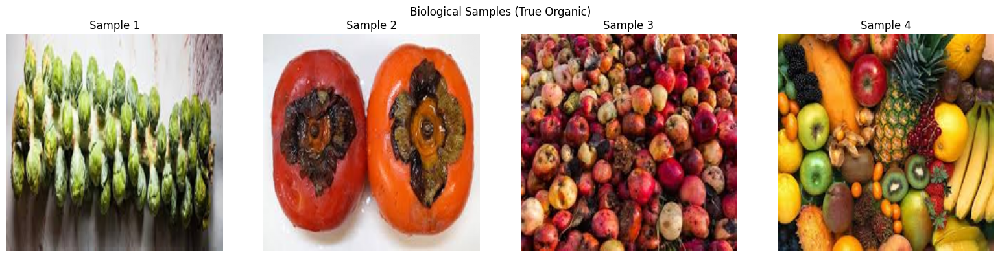

In [ ]:
# Cell: Ambil sample HANYA dari kelas biological (truly organic)

def get_biological_samples(dataset, num_samples=4):
    biological_samples = []

    for idx in range(len(dataset)):
        if len(biological_samples) >= num_samples:
            break

        img_path = dataset.df.iloc[idx]['path']
        label    = dataset.df.iloc[idx]['label']
        orig_cls = dataset.df.iloc[idx]['original_class']

        # Hanya ambil dari folder 'biological'
        if orig_cls == 'biological' and label == 0:
            # Load gambar original
            img_orig = Image.open(img_path).convert('RGB')
            img_orig = img_orig.resize((224, 224))
            img_np   = np.array(img_orig) / 255.0

            # Load dengan transform
            img_tensor = val_test_transform(img_orig)

            biological_samples.append({
                'path'      : img_path,
                'label'     : label,
                'img_np'    : img_np,
                'img_tensor': img_tensor,
                'orig_class': orig_cls
            })

            print(f"  Sample {len(biological_samples)}: {os.path.basename(img_path)}")

    return biological_samples

print("Mengambil sample dari kelas biological...")
biological_samples = get_biological_samples(test_dataset, num_samples=4)
print(f"\n✅ Total biological samples: {len(biological_samples)}")

# Preview gambar
fig, axes = plt.subplots(1, len(biological_samples), figsize=(16, 4))
for idx, sample in enumerate(biological_samples):
    axes[idx].imshow(sample['img_np'])
    axes[idx].set_title(f"Sample {idx+1}")
    axes[idx].axis('off')
plt.suptitle('Biological Samples (True Organic)', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
# Cek fungsi yang dibutuhkan
try:
    print(f"generate_gradcam_clean : {'✅' if callable(generate_gradcam_clean) else '❌'}")
    print(f"get_gradcam_target_layer: {'✅' if callable(get_gradcam_target_layer) else '❌'}")
    print(f"model_list             : {'✅' if model_list else '❌'}")
    print(f"PLOT_DIR               : {PLOT_DIR}")
except NameError as e:
    print(f"❌ Error: {e}")
    print("Jalankan cell definisi fungsi dulu!")

generate_gradcam_clean : ✅
get_gradcam_target_layer: ✅
model_list             : ✅
PLOT_DIR               : /content/drive/MyDrive/revisi_TA_jul


Generating Grad-CAM untuk Organic (Biological only)...


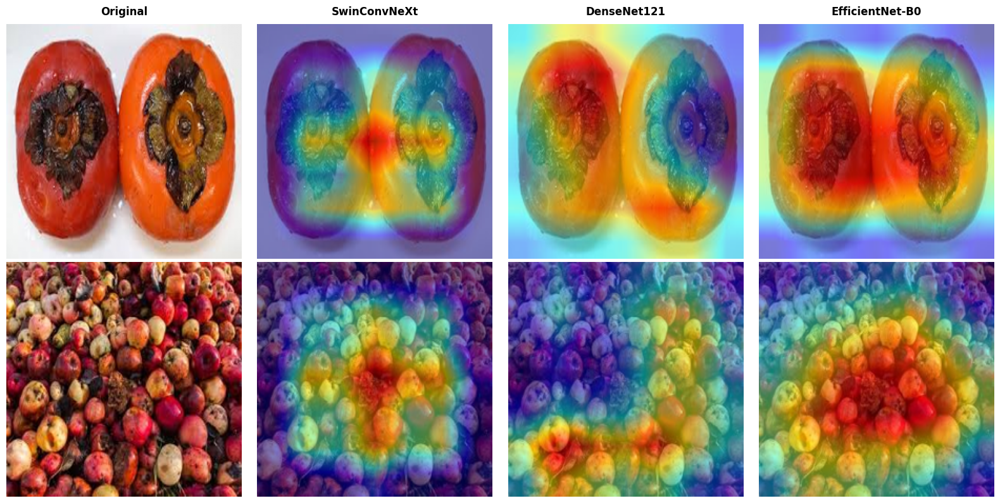

✅ Tersimpan: /content/drive/MyDrive/revisi_TA_jul/gradcam_organic_biological_clean.png


In [ ]:
# Cell: Generate Grad-CAM hanya dari biological samples
# Pakai Sample 2 dan Sample 3

selected_samples = [biological_samples[1],  # Sample 2 - buah busuk
                    biological_samples[2]]   # Sample 3 - tumpukan buah

# Generate Grad-CAM clean
print("Generating Grad-CAM untuk Organic (Biological only)...")
generate_gradcam_clean(
    samples    = selected_samples,
    class_name = 'Organic_biological',
    class_idx  = 0,
    save_dir   = PLOT_DIR,
    num_samples= 2
)

Mengambil sample inorganic yang representatif...
  Sample 1: brown-glass - brown-glass94.jpg
  Sample 2: green-glass - green-glass365.jpg
  Sample 3: white-glass - white-glass337.jpg
  Sample 4: brown-glass - brown-glass256.jpg

✅ Total samples: 4


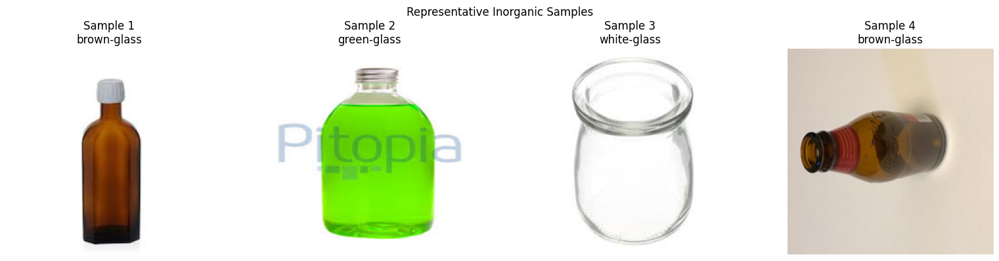

In [ ]:
# Filter inorganic samples yang lebih representatif
# Pilih dari kelas bottle/plastic/metal/glass

def get_representative_inorganic(dataset,
                                  target_classes=['plastic', 'metal',
                                                  'battery', 'brown-glass',
                                                  'green-glass', 'white-glass'],
                                  num_samples=4):
    selected = []

    for idx in range(len(dataset)):
        if len(selected) >= num_samples:
            break

        img_path = dataset.df.iloc[idx]['path']
        label    = dataset.df.iloc[idx]['label']
        orig_cls = dataset.df.iloc[idx]['original_class']

        if label == 1 and orig_cls in target_classes:
            img_orig = Image.open(img_path).convert('RGB')
            img_orig = img_orig.resize((224, 224))
            img_np   = np.array(img_orig) / 255.0
            img_tensor = val_test_transform(img_orig)

            selected.append({
                'path'      : img_path,
                'label'     : label,
                'img_np'    : img_np,
                'img_tensor': img_tensor,
                'orig_class': orig_cls
            })
            print(f"  Sample {len(selected)}: "
                  f"{orig_cls} - {os.path.basename(img_path)}")

    return selected

print("Mengambil sample inorganic yang representatif...")
inorganic_repr = get_representative_inorganic(test_dataset)
print(f"\n✅ Total samples: {len(inorganic_repr)}")

# Preview
fig, axes = plt.subplots(1, len(inorganic_repr), figsize=(16, 4))
for idx, sample in enumerate(inorganic_repr):
    axes[idx].imshow(sample['img_np'])
    axes[idx].set_title(f"Sample {idx+1}\n{sample['orig_class']}")
    axes[idx].axis('off')
plt.suptitle('Representative Inorganic Samples', fontsize=12)
plt.tight_layout()
plt.show()

Generating Grad-CAM untuk Inorganic (representative)...


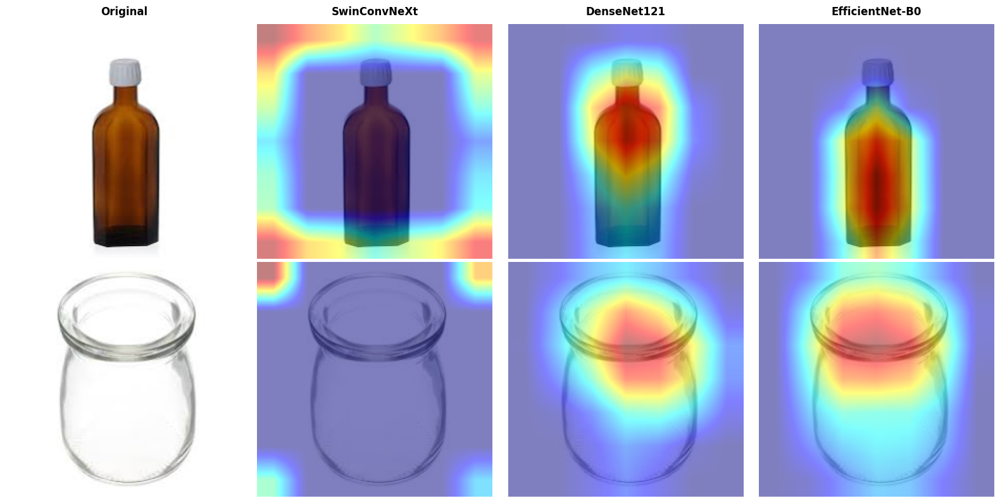

✅ Tersimpan: /content/drive/MyDrive/revisi_TA_jul/gradcam_inorganic_glass_clean.png


In [ ]:
# Pakai Sample 1 dan Sample 3
selected_inorganic = [inorganic_repr[0],   # Sample 1 - botol coklat
                      inorganic_repr[2]]   # Sample 3 - toples bening

print("Generating Grad-CAM untuk Inorganic (representative)...")
generate_gradcam_clean(
    samples    = selected_inorganic,
    class_name = 'Inorganic_glass',
    class_idx  = 1,
    save_dir   = PLOT_DIR,
    num_samples= 2
)

Generating Grad-CAM Organic (clean)...


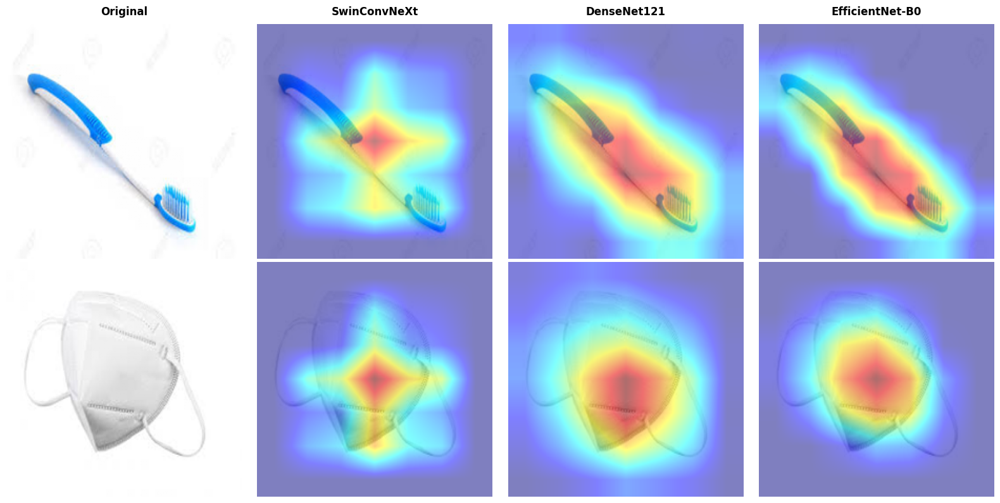

✅ Tersimpan: /content/drive/MyDrive/revisi_TA_jul/gradcam_organic_clean.png
Generating Grad-CAM Inorganic (clean)...


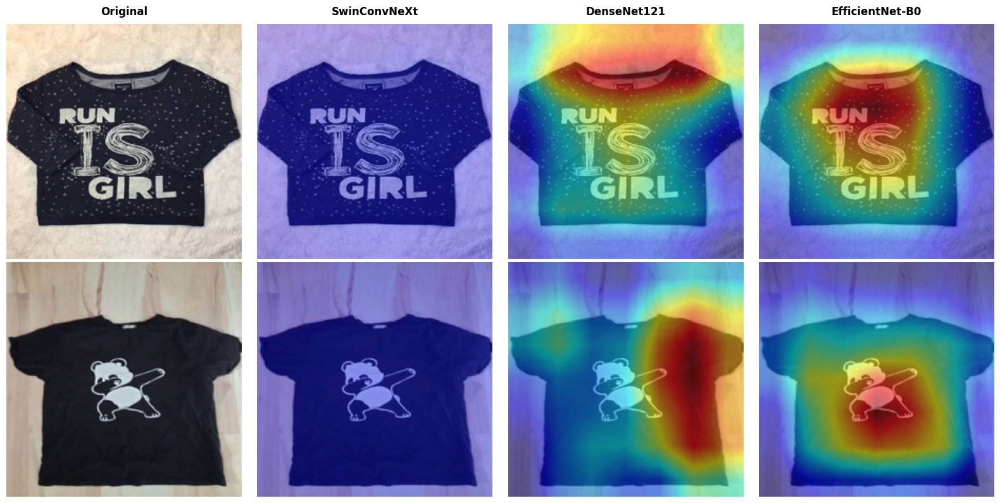

✅ Tersimpan: /content/drive/MyDrive/revisi_TA_jul/gradcam_inorganic_clean.png


In [ ]:
# Cell: Generate Grad-CAM tanpa ViT, hanya 2 sample

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
import numpy as np

# Hanya 3 model (tanpa ViT)
model_list = {
    'SwinConvNeXt'   : model_swin,
    'DenseNet121'    : model_densenet,
    'EfficientNet-B0': model_efficientnet
}

def generate_gradcam_clean(samples, class_name,
                            class_idx, save_dir,
                            num_samples=2):

    n_models  = len(model_list)
    n_samples = min(num_samples, len(samples))

    # n_samples baris, n_models+1 kolom (original + 3 model)
    fig, axes = plt.subplots(
        n_samples, n_models + 1,
        figsize=(4 * (n_models + 1), 4 * n_samples)
    )

    # Header kolom
    headers = ['Original'] + list(model_list.keys())
    for col, header in enumerate(headers):
        axes[0, col].set_title(header,
                               fontsize=12,
                               fontweight='bold',
                               pad=10)

    for row in range(n_samples):
        sample     = samples[row]
        img_np     = sample['img_np']
        img_tensor = sample['img_tensor']

        # Kolom 0: Original
        axes[row, 0].imshow(img_np)
        axes[row, 0].axis('off')

        # Kolom 1-3: Grad-CAM tiap model
        for col, (model_name, model) in enumerate(model_list.items()):
            try:
                target_layer = get_gradcam_target_layer(
                    model, model_name
                )
                cam = GradCAM(
                    model=model,
                    target_layers=target_layer
                )
                input_tensor = img_tensor.unsqueeze(0).to(device)
                targets      = [ClassifierOutputTarget(class_idx)]
                grayscale_cam = cam(
                    input_tensor=input_tensor,
                    targets=targets
                )
                visualization = show_cam_on_image(
                    img_np.astype(np.float32),
                    grayscale_cam[0],
                    use_rgb=True
                )
                axes[row, col + 1].imshow(visualization)
            except Exception as e:
                axes[row, col + 1].imshow(img_np)
                print(f"Error {model_name}: {e}")

            axes[row, col + 1].axis('off')

    plt.tight_layout()

    # Simpan
    filename  = f'gradcam_{class_name.lower()}_clean.png'
    save_path = os.path.join(PLOT_DIR, filename)
    plt.savefig(save_path, dpi=200, bbox_inches='tight')
    plt.show()
    print(f"✅ Tersimpan: {save_path}")

# Generate untuk Organic (2 sample)
print("Generating Grad-CAM Organic (clean)...")
generate_gradcam_clean(
    samples    = organic_samples,
    class_name = 'Organic',
    class_idx  = 0,
    save_dir   = PLOT_DIR,
    num_samples= 2
)

# Generate untuk Inorganic (2 sample)
print("Generating Grad-CAM Inorganic (clean)...")
generate_gradcam_clean(
    samples    = inorganic_samples,
    class_name = 'Inorganic',
    class_idx  = 1,
    save_dir   = PLOT_DIR,
    num_samples= 2
)